# EN4554 Assignment 2: CNNs
**Name:** YOUR NAME
**Index:** YOUR INDEX NUMBER
**GitHub:** https://github.com/YOUR_USERNAME/en4554-a2

All experiments were run on a GPU server (NVIDIA RTX 6000 Ada). The code below is the same code as in the
GitHub repository. Long training runs save their results after every configuration, so cells for
Tasks 2(c), 3 and 4 reload finished runs from `results/` instead of training them again.

## Setup: shared utilities (seeds, data, GPU augmentations, training loop)

In [1]:
import sys, os
from IPython.display import Image, display
import pandas as pd
pd.set_option('display.precision', 4)
DATA = '/home/anujaya/venumi/assignment02/data'
ARGV = ['--data', DATA, '--out', 'results']

import os, json, random, time, argparse, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")                     # no display on a server
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SPLIT_SEED = 0                            # the 45k/5k split never changes


# ----------------------------------------------------------------------------
# Arguments, seeds, output folders
# ----------------------------------------------------------------------------
def base_parser(desc):
    p = argparse.ArgumentParser(description=desc)
    p.add_argument("--data", default="./data", help="CIFAR-10 download folder")
    p.add_argument("--out", default="./results", help="results folder")
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--quick", action="store_true",
                   help="smoke test: tiny data + 1-2 epochs")
    p.add_argument("--fake", action="store_true",
                   help="random data instead of CIFAR-10 (offline testing only)")
    p.add_argument("--no-amp", action="store_true",
                   help="disable mixed precision")
    return p


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def out_dir(args, name):
    d = os.path.join(args.out, name)
    os.makedirs(d, exist_ok=True)
    return d


def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
def load_cifar10(args, load_test=False, device=DEVICE):
    """45k train / 5k val split of the CIFAR-10 training set, normalised per
    channel with the statistics of the 45k training images only."""
    if args.fake:
        rng = np.random.RandomState(123)
        xtr = rng.randint(0, 256, (50000, 32, 32, 3), dtype=np.uint8)
        ytr = rng.randint(0, 10, 50000)
        xte = rng.randint(0, 256, (10000, 32, 32, 3), dtype=np.uint8)
        yte = rng.randint(0, 10, 10000)
    else:
        from torchvision.datasets import CIFAR10
        tr = CIFAR10(args.data, train=True, download=True)
        xtr, ytr = tr.data, np.array(tr.targets)
        if load_test:                       # test set is touched ONLY in Task 4
            te = CIFAR10(args.data, train=False, download=True)
            xte, yte = te.data, np.array(te.targets)

    perm = np.random.RandomState(SPLIT_SEED).permutation(50000)
    tr_idx, va_idx = perm[:45000], perm[45000:]

    def to_tensor(a):                       # uint8 NHWC -> float NCHW in [0,1]
        return torch.from_numpy(a).permute(0, 3, 1, 2).float().div_(255)

    x = to_tensor(xtr)
    mean = x[tr_idx].mean(dim=(0, 2, 3))    # training statistics only
    std = x[tr_idx].std(dim=(0, 2, 3))

    def norm(t):
        return ((t - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)).to(device)

    y = torch.from_numpy(ytr).long()
    d = dict(xtr=norm(x[tr_idx]), ytr=y[tr_idx].to(device),
             xva=norm(x[va_idx]), yva=y[va_idx].to(device),
             mean=mean.tolist(), std=std.tolist())
    if load_test:
        d["xte"] = norm(to_tensor(xte))
        d["yte"] = torch.from_numpy(yte).long().to(device)
    if args.quick:                          # shrink everything for a smoke test
        d["xtr"], d["ytr"] = d["xtr"][:2000], d["ytr"][:2000]
        d["xva"], d["yva"] = d["xva"][:1000], d["yva"][:1000]
        if load_test:
            d["xte"], d["yte"] = d["xte"][:1000], d["yte"][:1000]
    return d


def batches(x, y, bs, shuffle=True):
    n = len(x)
    idx = torch.randperm(n, device=x.device) if shuffle else torch.arange(n, device=x.device)
    for i in range(0, n, bs):
        b = idx[i:i + bs]
        yield x[b], y[b]


# ----------------------------------------------------------------------------
# Augmentations (all implemented by hand, on GPU batches)
# ----------------------------------------------------------------------------
def random_flip(x):
    """Horizontal flip of each image with probability 0.5."""
    mask = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(mask[:, None, None, None], x.flip(3), x)


def random_crop(x, pad=4):
    """Zero-pad by `pad` pixels and take a random 32x32 crop per image."""
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = i[:, None] + torch.arange(H, device=x.device)[None]      # B x H
    cols = j[:, None] + torch.arange(W, device=x.device)[None]      # B x W
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[b, c, rows[:, None, :, None], cols[:, None, None, :]]


def cutout(x, size=16):
    """Cutout (DeVries & Taylor 2017): zero a random size x size square per
    image. The centre can be near the border, so the square may be clipped."""
    B, C, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]
    xs = torch.arange(W, device=x.device)[None, None, :]
    h = size // 2
    inside = (ys >= cy - h) & (ys < cy + h) & (xs >= cx - h) & (xs < cx + h)
    return x * (~inside)[:, None].to(x.dtype)


def mixup(x, y, alpha):
    """Mixup (Zhang et al. 2018). Returns mixed inputs, both label sets and
    lambda; the loss is lam*CE(out, y_a) + (1-lam)*CE(out, y_b)."""
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(x.shape[0], device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam


def make_aug(names, cutout_size=16):
    """names: list from {'flip','crop','cutout'} -> function x -> x."""
    names = list(names or [])
    if not names:
        return None

    def aug(x):
        if "flip" in names:
            x = random_flip(x)
        if "crop" in names:
            x = random_crop(x)
        if "cutout" in names:
            x = cutout(x, cutout_size)
        return x
    return aug


# ----------------------------------------------------------------------------
# Training / evaluation
# ----------------------------------------------------------------------------
def autocast(enabled):
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                          enabled=enabled and DEVICE.type == "cuda")


@torch.no_grad()
def evaluate(model, x, y, bs=1000, amp=True):
    model.eval()
    tot_loss, correct = 0.0, 0
    for i in range(0, len(x), bs):
        with autocast(amp):
            out = model(x[i:i + bs])
        out = out.float()
        tot_loss += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return tot_loss / len(x), correct / len(x)


def train(model, data, epochs, optimizer, scheduler=None, bs=128, aug=None,
          mixup_alpha=0.0, label_smoothing=0.0, amp=True, xtr=None, ytr=None,
          clean_train_eval=False, tag=""):
    """Generic training loop. `scheduler` is stepped every iteration.
    Returns a history dict with per-iteration and per-epoch curves."""
    xtr = data["xtr"] if xtr is None else xtr
    ytr = data["ytr"] if ytr is None else ytr
    use_amp = amp and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    H = {k: [] for k in ["iter_loss", "train_loss", "train_acc", "val_loss",
                         "val_acc", "train_acc_clean", "train_loss_clean", "lr"]}
    H["diverged"] = False
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        losses, correct, seen = [], torch.zeros((), device=DEVICE), 0
        for xb, yb in batches(xtr, ytr, bs):
            if aug is not None:
                xb = aug(xb)
            with autocast(use_amp):
                if mixup_alpha > 0:
                    xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                    out = model(xb)
                    loss = (lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing)
                            + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing))
                else:
                    out = model(xb)
                    loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
            losses.append(loss.detach().float())
            correct += (out.argmax(1) == yb).sum()
            seen += len(yb)
        ep_losses = torch.stack(losses).cpu().tolist()
        H["iter_loss"] += ep_losses
        H["train_loss"].append(float(np.mean(ep_losses)))
        H["train_acc"].append(correct.item() / seen)
        H["lr"].append(optimizer.param_groups[0]["lr"])
        vl, va = evaluate(model, data["xva"], data["yva"], amp=amp)
        H["val_loss"].append(vl)
        H["val_acc"].append(va)
        if clean_train_eval:                # accuracy on un-augmented train set
            tl, ta = evaluate(model, xtr, ytr, amp=amp)
            H["train_loss_clean"].append(tl)
            H["train_acc_clean"].append(ta)
        print(f"[{tag}] ep {ep + 1:3d}/{epochs} loss {H['train_loss'][-1]:.4f} "
              f"train_acc {H['train_acc'][-1]:.4f} val_acc {va:.4f} "
              f"({time.time() - t0:.1f}s)", flush=True)
        if not math.isfinite(H["train_loss"][-1]):
            print(f"[{tag}] diverged (non-finite loss); stopping this run.")
            H["diverged"] = True
            break
    return H


def smooth(v, k=50):
    v = np.asarray(v, dtype=float)
    if len(v) < k:
        return v
    return np.convolve(v, np.ones(k) / k, mode="valid")


def epochs_for(args, full):
    return 2 if args.quick else full

In [2]:
# Notebook helper: print a compact training log from a saved history
def print_log(results, every=5):
    for name, r in results.items():
        H = r['hist']
        n = len(H['val_acc'])
        for e in sorted(set(list(range(every - 1, n, every)) + [n - 1])):
            print(f"[{name}] ep {e + 1:3d}/{n} loss {H['train_loss'][e]:.4f} "
                  f"train_acc {H['train_acc'][e]:.4f} val_acc {H['val_acc'][e]:.4f}")

## Data split and preprocessing

In [3]:
set_seed(0)
args = base_parser('setup').parse_args(ARGV)
data = load_cifar10(args)
print('device:', DEVICE)
print('train:', tuple(data['xtr'].shape), ' val:', tuple(data['xva'].shape))
print('mean (45k train images):', [round(m, 4) for m in data['mean']])
print('std  (45k train images):', [round(s, 4) for s in data['std']])
print('normalised train mean per channel:', data['xtr'].mean(dim=(0, 2, 3)).tolist())

device: cuda
train: (45000, 3, 32, 32)  val: (5000, 3, 32, 32)
mean (45k train images): [0.4916, 0.4823, 0.4462]
std  (45k train images): [0.247, 0.2434, 0.2615]
normalised train mean per channel: [3.1765407584316563e-06, -3.8140192373248283e-06, -6.022135607963719e-07]


## Task 1: Backpropagation

### 1(a) Linear, ReLU, Sigmoid and softmax cross-entropy layers

In [4]:
# Task 1(a): layers with explicit forward/backward, assembled into an MLP
class Linear:
    def __init__(self, din, dout, init="kaiming", dtype=torch.float32, device=DEVICE):
        std = {"kaiming": math.sqrt(2.0 / din),          # He, for ReLU
               "xavier": math.sqrt(2.0 / (din + dout)),  # Glorot, for sigmoid/tanh
               "lecun": math.sqrt(1.0 / din)}[init]
        self.W = torch.randn(din, dout, dtype=dtype, device=device) * std
        self.b = torch.zeros(dout, dtype=dtype, device=device)
        self.dW, self.db = torch.zeros_like(self.W), torch.zeros_like(self.b)

    def forward(self, x):                 # y = x W + b
        self.x = x
        return x @ self.W + self.b

    def backward(self, g):                # g = dL/dy  (N x dout)
        self.dW = self.x.T @ g            # dL/dW = x^T g
        self.db = g.sum(0)                # dL/db = sum over batch
        return g @ self.W.T               # dL/dx = g W^T

    def params(self):
        return [self.W, self.b]

    def grads(self):
        return [self.dW, self.db]


class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask

    def backward(self, g):                # derivative is 1 where x > 0
        return g * self.mask

    def params(self):
        return []

    def grads(self):
        return []


class Sigmoid:
    def forward(self, x):
        self.s = 1.0 / (1.0 + torch.exp(-x))
        return self.s

    def backward(self, g):                # sigma' = sigma (1 - sigma) <= 1/4
        return g * self.s * (1 - self.s)

    def params(self):
        return []

    def grads(self):
        return []


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values   # numerical stability
        logp = z - z.exp().sum(1, keepdim=True).log()       # log-softmax
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y)), y].mean()

    def backward(self):                   # dL/dz = (softmax - onehot) / N
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)


class MLP:
    def __init__(self, sizes, act="relu", init=None, dtype=torch.float32, device=DEVICE):
        init = init or ("kaiming" if act == "relu" else "xavier")
        self.layers = []
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(a, b, init, dtype, device))
            if i < len(sizes) - 2:
                self.layers.append(ReLU() if act == "relu" else Sigmoid())
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):
        g = self.criterion.backward()
        for layer in reversed(self.layers):
            g = layer.backward(g)

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def params(self):
        return [p for l in self.layers for p in l.params()]

    def grads(self):
        return [g for l in self.layers for g in l.grads()]

    def sgd_step(self, lr):
        for p, g in zip(self.params(), self.grads()):
            p.sub_(lr * g)

### 1(b) Gradient check

In [5]:
# Task 1(b): gradient check vs autograd and centred finite differences (float64)
def autograd_grads(mlp, x, y):
    """Same network rebuilt with torch ops + autograd, sharing the weights."""
    ps = [p.detach().clone().requires_grad_(True) for p in mlp.params()]
    h, k = x, 0
    for layer in mlp.layers:
        if isinstance(layer, Linear):
            h = h @ ps[k] + ps[k + 1]
            k += 2
        elif isinstance(layer, ReLU):
            h = torch.relu(h)
        else:
            h = torch.sigmoid(h)
    loss = F.cross_entropy(h, y)
    loss.backward()
    return [p.grad for p in ps]


def finite_diff(mlp, x, y, p, idx, eps=1e-6):
    """Centred difference (L(p+eps) - L(p-eps)) / 2eps at flat indices idx."""
    flat, out = p.view(-1), []
    for i in idx:
        old = flat[i].item()
        flat[i] = old + eps
        lp = mlp.loss(x, y).item()
        flat[i] = old - eps
        lm = mlp.loss(x, y).item()
        flat[i] = old
        out.append((lp - lm) / (2 * eps))
    return torch.tensor(out, dtype=p.dtype, device=p.device)


def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-30)).item()


def gradient_check(mlp, x, y, n_fd=None, name=""):
    mlp.loss(x, y)
    mlp.backward()
    manual = [g.clone() for g in mlp.grads()]
    auto = autograd_grads(mlp, x, y)
    gen = torch.Generator().manual_seed(0)
    rows = []
    for k, (p, gm, ga) in enumerate(zip(mlp.params(), manual, auto)):
        n = p.numel()
        idx = torch.arange(n) if (n_fd is None or n <= n_fd) else torch.randperm(n, generator=gen)[:n_fd]
        fd = finite_diff(mlp, x, y, p, idx.tolist())
        gm_s = gm.reshape(-1)[idx.to(gm.device)]
        rows.append(dict(
            model=name, param=f"{'W' if k % 2 == 0 else 'b'}{k // 2 + 1}", shape=list(p.shape),
            rel_err_autograd=rel_err(gm, ga),
            allclose_autograd=bool(torch.allclose(gm, ga, rtol=1e-6, atol=1e-10)),
            n_fd_entries=len(idx), rel_err_fd=rel_err(gm_s, fd),
            allclose_fd=bool(torch.allclose(gm_s, fd, rtol=1e-4, atol=1e-7))))
    return rows


args = base_parser("Task 1").parse_args(ARGV)
set_seed(args.seed)
od = out_dir(args, "task1")
data = load_cifar10(args)
Xtr, Xva = data["xtr"].flatten(1), data["xva"].flatten(1)
ytr, yva = data["ytr"], data["yva"]

# ---------------- (b) gradient check (float64) ----------------
print("== Task 1(b): gradient check ==")
rows = []
torch.manual_seed(0)
xs = torch.randn(8, 20, dtype=torch.float64, device=DEVICE)
ys = torch.randint(0, 10, (8,), device=DEVICE)
for act in ["relu", "sigmoid"]:
    tiny = MLP([20, 16, 12, 10], act=act, dtype=torch.float64)
    rows += gradient_check(tiny, xs, ys, n_fd=None, name=f"tiny-{act} (all entries)")
xb, yb = Xtr[:16].double(), ytr[:16]
big = MLP([3072, 128, 64, 10], act="relu", dtype=torch.float64)
rows += gradient_check(big, xb, yb, n_fd=40, name="cifar-relu (40 random entries/tensor for FD)")
save_json(rows, os.path.join(od, "gradcheck.json"))
import pandas as pd
df = pd.DataFrame(rows)
df.to_csv(os.path.join(od, "gradcheck.csv"), index=False)
print(df.to_string(index=False))

== Task 1(b): gradient check ==


                                       model param       shape  rel_err_autograd  allclose_autograd  n_fd_entries  rel_err_fd  allclose_fd
                     tiny-relu (all entries)    W1    [20, 16]        0.0000e+00               True           320  6.9475e-10         True
                     tiny-relu (all entries)    b1        [16]        0.0000e+00               True            16  5.7348e-10         True
                     tiny-relu (all entries)    W2    [16, 12]        0.0000e+00               True           192  3.2673e-10         True
                     tiny-relu (all entries)    b2        [12]        0.0000e+00               True            12  3.2941e-10         True
                     tiny-relu (all entries)    W3    [12, 10]        0.0000e+00               True           120  3.1817e-10         True
                     tiny-relu (all entries)    b3        [10]        0.0000e+00               True            10  3.3065e-10         True
                  tiny-sigm

**Discussion**

- **vs autograd:** the relative error is exactly 0 for every ReLU-network parameter and at most 9e-17 for the sigmoid network. Float64 machine epsilon is about 2.2e-16, so the manual gradients are identical to autograd up to rounding, and `allclose` is `True` for all 18 parameter tensors. The sigmoid case is not exactly 0 only because `σ(z)(1−σ(z))` is computed in a slightly different order from PyTorch.
- **vs finite differences:** the error is 3e-10 to 2e-8. This is larger, but expected, because the centred difference is itself only an approximation:
  - truncation error O(ε²) from the Taylor expansion, and
  - round-off error O(machine ε / ε) from subtracting two nearly equal losses.
  - With ε ≈ 1e-6 both terms are around 1e-10 to 1e-9, which is what we see. Sigmoid has slightly larger FD error (up to 1.6e-8) because its curvature makes the O(ε²) term bigger than for piecewise-linear ReLU.
- The check covers every entry of the tiny networks and 40 random entries per tensor of the full CIFAR-sized network (3072→128→64→10), so the shapes used in training are tested too.

Overall, the forward/backward passes of Linear, ReLU, Sigmoid and softmax cross-entropy are correct.

### 1(c) Training the MLP with SGD

In [6]:
# Task 1(c): train the MLP with manual backprop + SGD on flattened CIFAR-10
# ---------------- (c) train with SGD ----------------
print("== Task 1(c): SGD training ==")
set_seed(args.seed)
epochs, lr, bs = epochs_for(args, 30), 0.02, 128
mlp = MLP([3072, 512, 256, 10], act="relu")
H = dict(iter_loss=[], train_loss=[], val_loss=[], val_acc=[])
for ep in range(epochs):
    ls = []
    for x, y in batches(Xtr, ytr, bs):
        loss = mlp.loss(x, y)
        mlp.backward()
        mlp.sgd_step(lr)
        ls.append(loss.item())
    with torch.no_grad():
        logits = mlp.forward(Xva)
        vl = mlp.criterion.forward(logits, yva).item()
        va = (logits.argmax(1) == yva).float().mean().item()
    H["iter_loss"] += ls
    H["train_loss"].append(float(np.mean(ls)))
    H["val_loss"].append(vl)
    H["val_acc"].append(va)
    print(f"ep {ep + 1:2d} train_loss {H['train_loss'][-1]:.4f} val_loss {vl:.4f} val_acc {va:.4f}", flush=True)
save_json(H, os.path.join(od, "mlp_sgd_history.json"))
save_json(dict(final_val_acc=H["val_acc"][-1], best_val_acc=max(H["val_acc"]),
               epochs=epochs, lr=lr, batch_size=bs, arch=[3072, 512, 256, 10]),
          os.path.join(od, "mlp_sgd_summary.json"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(H["iter_loss"], alpha=0.3, label="mini-batch loss")
ax[0].plot(np.arange(len(smooth(H["iter_loss"]))) + 49, smooth(H["iter_loss"]), label="moving avg (50)")
ax[0].set(xlabel="iteration", ylabel="cross-entropy", title="MLP training loss (manual backprop, SGD)")
ax[0].legend()
e = np.arange(1, len(H["val_acc"]) + 1)
ax[1].plot(e, H["train_loss"], "o-", label="train loss")
ax[1].plot(e, H["val_loss"], "s-", label="val loss")
ax2 = ax[1].twinx()
ax2.plot(e, H["val_acc"], "g^-", label="val acc")
ax2.set_ylabel("validation accuracy")
ax[1].set(xlabel="epoch", ylabel="loss", title=f"final val acc = {H['val_acc'][-1]:.3f}")
ax[1].legend(loc="center right")
fig.tight_layout()
fig.savefig(os.path.join(od, "mlp_sgd_training.png"), dpi=150)
plt.close(fig)

== Task 1(c): SGD training ==


ep  1 train_loss 1.7457 val_loss 1.6449 val_acc 0.4218


ep  2 train_loss 1.4782 val_loss 1.5462 val_acc 0.4620


ep  3 train_loss 1.3573 val_loss 1.5247 val_acc 0.4680


ep  4 train_loss 1.2686 val_loss 1.5015 val_acc 0.4836


...

ep 26 train_loss 0.2826 val_loss 2.0924 val_acc 0.4786


ep 27 train_loss 0.2624 val_loss 1.9903 val_acc 0.5066


ep 28 train_loss 0.2391 val_loss 2.0750 val_acc 0.5008


ep 29 train_loss 0.2179 val_loss 2.0488 val_acc 0.5150


ep 30 train_loss 0.1953 val_loss 2.1461 val_acc 0.5026


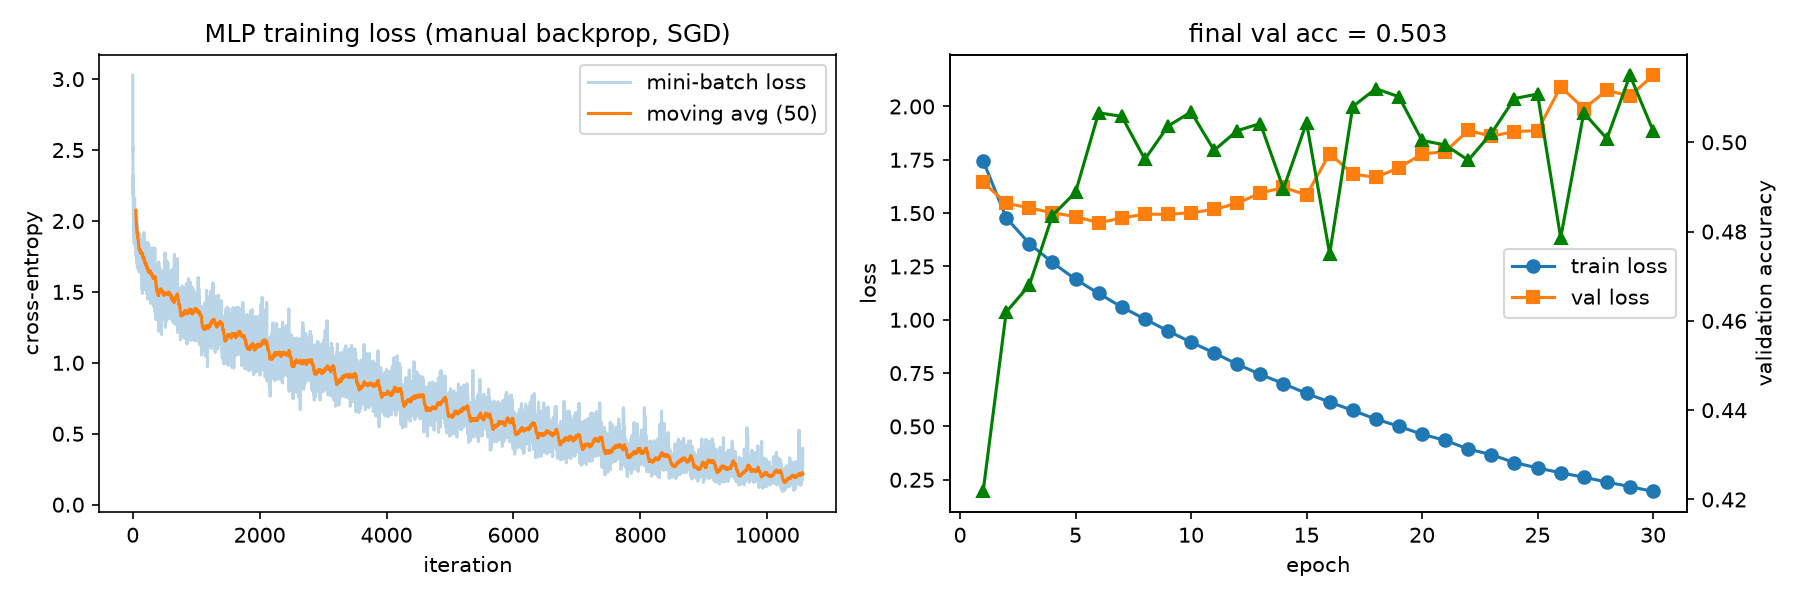

In [7]:
display(Image(filename='results/task1/mlp_sgd_training.png'))

**Discussion**

- The MLP (3072→512→256→10, SGD lr 0.02, 30 epochs) reaches about **50% validation accuracy by epoch 5** and then stays there: the best is 51.5% (epoch 29) and the final value is 50.3%.
- The **training loss keeps decreasing** all the way (1.75 → 0.20), but the **validation loss is lowest at epoch 6 (1.45) and then climbs to 2.15**. This growing train/val gap is overfitting: the network is memorising the 45k training images rather than learning features that transfer. Accuracy stays flat while the validation loss rises because the model becomes over-confident on the images it gets wrong.
- An MLP on raw pixels is limited for images:
  - Flattening throws away the 2-D layout, so the network has no notion of neighbouring pixels.
  - There is no weight sharing, so a pattern learnt at one position has to be learnt again at every other position (no translation invariance).
  - This costs ~1.7M parameters in the first layer alone, which makes memorisation easy.

Early stopping around epoch 6 would give the best model, and it still tops out at about 50%. The CNNs in Task 2(c) reach ~75% with far fewer parameters.

### 1(d) Gradient norms with sigmoid and ReLU

In [8]:
# Task 1(d): per-layer gradient norms at initialisation for a 10-layer MLP
# ---------------- (d) gradient norms in a 10-layer MLP ----------------
print("== Task 1(d): per-layer gradient norms ==")
sizes = [3072] + [256] * 9 + [10]          # 10 Linear layers
x, y = Xtr[:512], ytr[:512]
configs = {"sigmoid (Xavier init)": ("sigmoid", "xavier"),
           "ReLU (Kaiming init)": ("relu", "kaiming"),
           "sigmoid (Kaiming init)": ("sigmoid", "kaiming"),
           "ReLU (Xavier init)": ("relu", "xavier")}
norms = {}
for name, (act, init) in configs.items():
    runs = []
    for s in range(5):                      # average over 5 random inits
        torch.manual_seed(s)
        net = MLP(sizes, act=act, init=init)
        net.loss(x, y)
        net.backward()
        runs.append([l.dW.norm().item() for l in net.linears()])
    norms[name] = np.mean(runs, 0).tolist()
    print(name, ["%.2e" % v for v in norms[name]])
save_json(norms, os.path.join(od, "grad_norms.json"))
fig, ax = plt.subplots(figsize=(7, 4.5))
styles = ["o-", "s-", "o--", "s--"]
for (name, v), st in zip(norms.items(), styles):
    ax.semilogy(range(1, 11), v, st, label=name)
ax.set(xlabel="layer (1 = closest to input)", ylabel=r"$\|\partial L/\partial W_\ell\|_F$",
       title="Per-layer gradient norm at initialisation, 10-layer MLP")
ax.set_xticks(range(1, 11))
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(od, "grad_norms.png"), dpi=150)
plt.close(fig)
print("Task 1 done ->", od)

== Task 1(d): per-layer gradient norms ==


sigmoid (Xavier init) ['1.20e-05', '2.21e-05', '9.35e-05', '3.94e-04', '1.63e-03', '6.96e-03', '2.99e-02', '1.27e-01', '5.40e-01', '1.65e+00']
ReLU (Kaiming init) ['4.23e+00', '1.89e+00', '2.51e+00', '2.90e+00', '3.39e+00', '4.05e+00', '4.20e+00', '4.61e+00', '4.92e+00', '5.47e+00']
sigmoid (Kaiming init) ['1.30e-04', '1.80e-04', '5.80e-04', '1.82e-03', '5.55e-03', '1.77e-02', '5.64e-02', '1.79e-01', '5.59e-01', '1.77e+00']


ReLU (Xavier init) ['1.56e-01', '6.36e-02', '6.54e-02', '6.67e-02', '6.97e-02', '6.67e-02', '6.29e-02', '6.06e-02', '5.67e-02', '3.98e-02']


Task 1 done -> results/task1


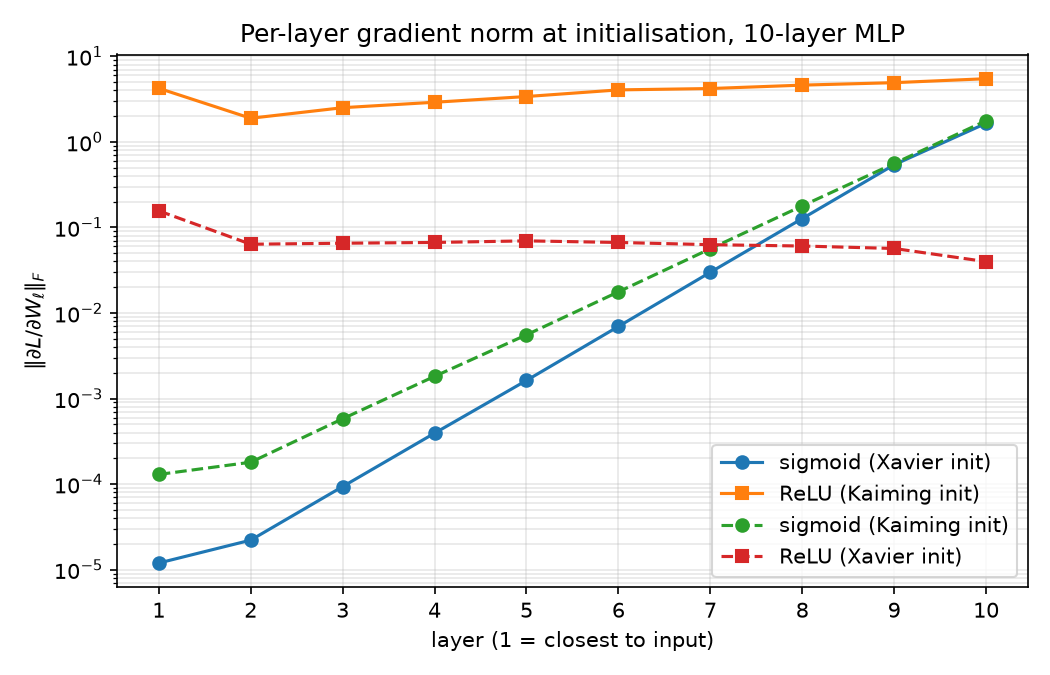

In [9]:
display(Image(filename='results/task1/grad_norms.png'))

**Discussion**

- **Sigmoid (Xavier):** the gradient norm falls from 1.65 at layer 10 to 1.2e-5 at layer 1, about **1.4×10⁵ times smaller**, and roughly 4× smaller per layer (the line is straight on the log scale).
  - The sigmoid derivative σ'(z) = σ(1−σ) is at most 1/4. Each layer the backward signal is multiplied by σ' ≤ 1/4 (times the weights), so it shrinks geometrically: 0.25⁹ ≈ 4×10⁻⁶ over 9 layers, the same order as observed.
  - The first layers would therefore barely learn. This is the **vanishing gradient** problem.
- **ReLU (Kaiming):** the norm stays between about 2 and 5.5 across all 10 layers. ReLU's derivative is exactly 1 for active units (0 otherwise), and Kaiming init (variance 2/fan_in) compensates for the half of the units that are off, so the variance of the signal is kept constant from layer to layer in both directions.
- **Mismatched initialisations** separate the effect of the activation from the effect of the init:
  - **Sigmoid with Kaiming init** still vanishes at the same rate (1.77 → 1.3e-4). Larger weights cannot fix it, because the ≤ 1/4 factor comes from the activation itself.
  - **ReLU with Xavier init** is still flat across layers, but every layer's gradient is about 50× smaller (~0.06). Xavier (variance 1/fan_in) does not account for ReLU zeroing half the units, so the activations shrink in the forward pass and every gradient is scaled down. Its shape stays flat because ReLU does not multiply by a factor < 1 per layer.

So the activation function decides whether gradients vanish *with depth*, and the initialisation sets their overall *scale*.

## Task 2: Optimizers

### 2(a) SGD with momentum and Adam

In [10]:
# Task 2(a): SGD-momentum and Adam (with bias correction) as torch.optim.Optimizer subclasses
import math


class MySGD(torch.optim.Optimizer):
    """v_t = mu * v_{t-1} + g_t   (v_1 = g_1);   theta <- theta - lr * v_t
    (with nesterov: theta <- theta - lr * (g_t + mu * v_t)).
    weight_decay adds wd * theta to the gradient (L2 regularisation)."""
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0, nesterov=False):
        if lr <= 0:
            raise ValueError("lr must be positive")
        super().__init__(params, dict(lr=lr, momentum=momentum,
                                      weight_decay=weight_decay, nesterov=nesterov))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu = group["lr"], group["momentum"]
            wd, nesterov = group["weight_decay"], group["nesterov"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                if mu != 0:
                    state = self.state[p]
                    buf = state.get("momentum_buffer")
                    if buf is None:
                        buf = g.clone()
                        state["momentum_buffer"] = buf
                    else:
                        buf.mul_(mu).add_(g)
                    g = g.add(buf, alpha=mu) if nesterov else buf
                p.add_(g, alpha=-lr)
        return loss


class MyAdam(torch.optim.Optimizer):
    """m_t = b1 m + (1-b1) g,   v_t = b2 v + (1-b2) g^2
    m_hat = m_t / (1-b1^t),     v_hat = v_t / (1-b2^t)      (bias correction)
    theta <- theta - lr * m_hat / (sqrt(v_hat) + eps)
    Implemented in the algebraically identical form PyTorch uses:
    theta <- theta - (lr/(1-b1^t)) * m_t / (sqrt(v_t)/sqrt(1-b2^t) + eps)."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2) = group["lr"], group["betas"]
            eps, wd = group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                state = self.state[p]
                if len(state) == 0:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["step"] += 1
                t, m, v = state["step"], state["m"], state["v"]
                m.mul_(b1).add_(g, alpha=1 - b1)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)
                bc1 = 1 - b1 ** t
                bc2 = 1 - b2 ** t
                denom = (v.sqrt() / math.sqrt(bc2)).add_(eps)
                p.addcdiv_(m, denom, value=-lr / bc1)
        return loss

In [11]:
# Task 2(a): compare against torch.optim for 200 steps
import copy
def match_test(data, my_cls, torch_cls, kw, steps=100, label=""):
    """Train two identical copies, one per optimiser, on the same batches
    (float64, CPU so the arithmetic is deterministic)."""
    torch.manual_seed(0)
    base = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(8 * 16 * 16, 10)).double()
    m1, m2 = copy.deepcopy(base), copy.deepcopy(base)
    o1, o2 = my_cls(m1.parameters(), **kw), torch_cls(m2.parameters(), **kw)
    X = data["xtr"][:2048].cpu().double()
    Y = data["ytr"][:2048].cpu()
    g = torch.Generator().manual_seed(1)
    l1s, l2s = [], []
    for _ in range(steps):
        idx = torch.randint(0, len(X), (64,), generator=g)
        for m, o, ls in ((m1, o1, l1s), (m2, o2, l2s)):
            o.zero_grad()
            loss = F.cross_entropy(m(X[idx]), Y[idx])
            loss.backward()
            o.step()
            ls.append(loss.item())
    diff = max((p1 - p2).abs().max().item() for p1, p2 in zip(m1.parameters(), m2.parameters()))
    ok = all(torch.allclose(p1, p2, rtol=1e-7, atol=1e-10)
             for p1, p2 in zip(m1.parameters(), m2.parameters()))
    print(f"{label:35s} max|param diff| = {diff:.2e}  allclose = {ok}")
    return dict(config=label, max_abs_param_diff=diff, allclose=ok), l1s, l2s


p = base_parser("Task 2")
p.add_argument("--epochs", type=int, default=15)
args = p.parse_args(ARGV)
set_seed(args.seed)
od = out_dir(args, "task2")
data = load_cifar10(args)

# ======================= (a) =======================
print("== Task 2(a): custom optimisers vs torch.optim ==")
tests = [
    (MySGD, torch.optim.SGD, dict(lr=0.05), "SGD (plain)"),
    (MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9), "SGD momentum 0.9"),
    (MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9, weight_decay=5e-4), "SGD momentum 0.9 + wd"),
    (MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9, nesterov=True), "SGD Nesterov 0.9"),
    (MyAdam, torch.optim.Adam, dict(lr=1e-3), "Adam lr=1e-3"),
    (MyAdam, torch.optim.Adam, dict(lr=1e-3, betas=(0.8, 0.99), weight_decay=1e-4), "Adam betas=(0.8,0.99) + wd"),
]
rows, curves = [], {}
for my, tc, kw, label in tests:
    r, l1, l2 = match_test(data, my, tc, kw, steps=20 if args.quick else 200, label=label)
    rows.append(r)
    curves[label] = (l1, l2)
import pandas as pd
pd.DataFrame(rows).to_csv(os.path.join(od, "optimizer_match.csv"), index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, label in zip(ax, ["SGD momentum 0.9", "Adam lr=1e-3"]):
    l1, l2 = curves[label]
    a.plot(l1, lw=3, alpha=0.5, label="my implementation")
    a.plot(l2, "k--", lw=1, label="torch.optim")
    a.set(title=label, xlabel="step", ylabel="mini-batch loss")
    a.legend()
fig.tight_layout()
fig.savefig(os.path.join(od, "optimizer_match.png"), dpi=150)
plt.close(fig)

display(pd.read_csv(os.path.join(od, 'optimizer_match.csv')))

== Task 2(a): custom optimisers vs torch.optim ==


SGD (plain)                         max|param diff| = 0.00e+00  allclose = True


SGD momentum 0.9                    max|param diff| = 0.00e+00  allclose = True


SGD momentum 0.9 + wd               max|param diff| = 0.00e+00  allclose = True


SGD Nesterov 0.9                    max|param diff| = 0.00e+00  allclose = True


Adam lr=1e-3                        max|param diff| = 1.11e-16  allclose = True


Adam betas=(0.8,0.99) + wd          max|param diff| = 1.11e-16  allclose = True


,config,max_abs_param_diff,allclose
0,SGD (plain),0.0000e+00,True
1,SGD momentum 0.9,0.0000e+00,True
2,SGD momentum 0.9 + wd,0.0000e+00,True
3,SGD Nesterov 0.9,0.0000e+00,True
4,Adam lr=1e-3,1.1102e-16,True
5,"Adam betas=(0.8,0.99) + wd",1.1102e-16,True


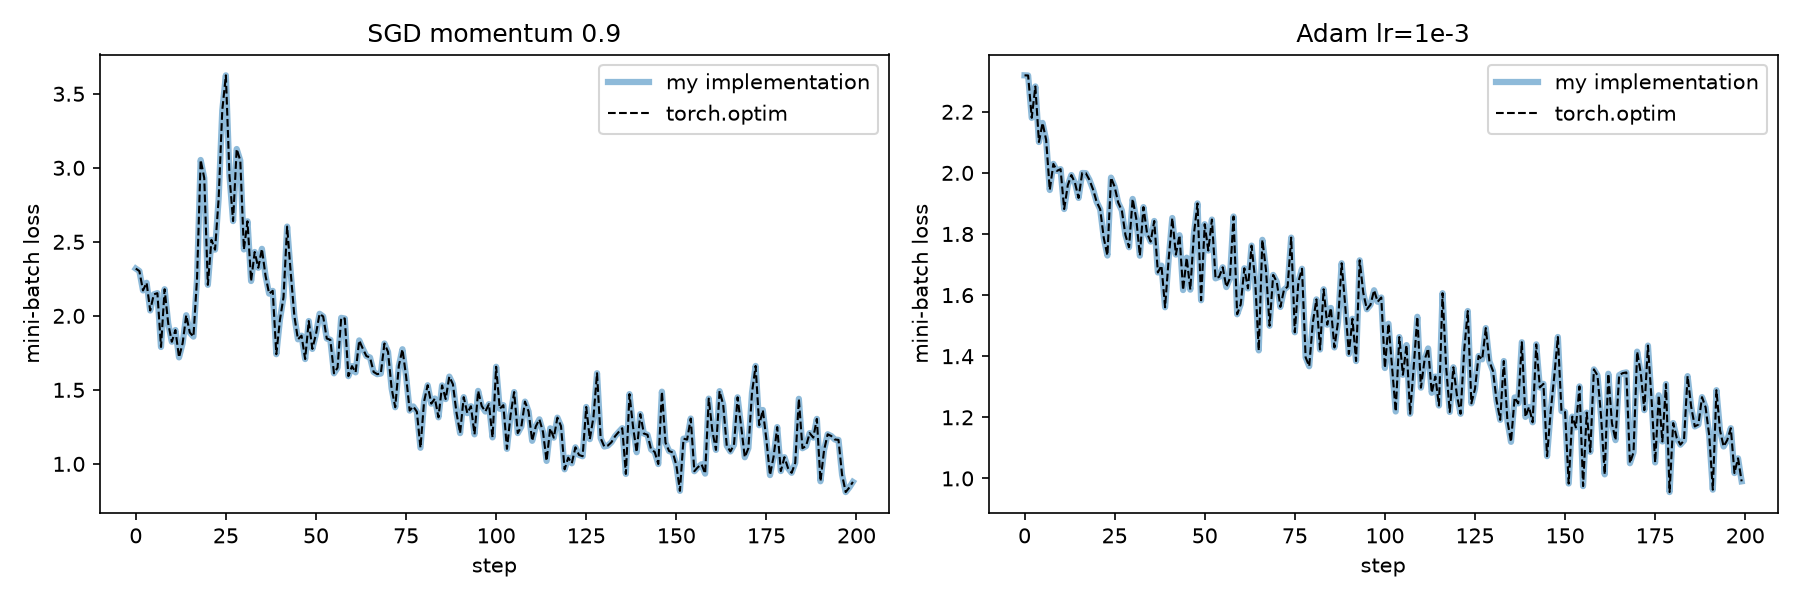

In [12]:
display(Image(filename='results/task2/optimizer_match.png'))

**Discussion**

- **SGD (plain, momentum, momentum + weight decay, Nesterov):** the maximum parameter difference from `torch.optim.SGD` after 200 steps is **exactly 0**. The implementation performs the same floating-point operations in the same order as PyTorch, so the results are bit-for-bit identical.
- **Adam (default and with betas = (0.8, 0.99) + weight decay):** the difference is **1.1e-16**, i.e. one unit of float64 rounding. The bias-corrected update is mathematically the same as PyTorch's; only the order of a few operations differs.
- `allclose` is `True` in all six configurations, and the plot shows the two parameter trajectories lying on top of each other.

Both optimizers, including momentum, Nesterov, weight decay and Adam's bias correction, are implemented correctly.

### 2(b) Optimizer paths on a quadratic

In [13]:
# Task 2(b): trajectories on f(x, y) = 0.5 (x^2 + 50 y^2)
def quad_traj(opt_cls, kw, start=(-10.0, 1.0), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kw)
    traj = [p.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad()
        f = 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)
        f.backward()
        opt.step()
        traj.append(p.detach().clone().numpy())
    return np.array(traj)


def fquad(x, y):
    return 0.5 * (x ** 2 + 50 * y ** 2)


# ======================= (b) =======================
print("== Task 2(b): trajectories on f = 0.5(x^2 + 50 y^2) ==")
runs = {
    "SGD (lr=0.035)": (MySGD, dict(lr=0.035)),
    "SGD+momentum (lr=0.01, mu=0.9)": (MySGD, dict(lr=0.01, momentum=0.9)),
    "Adam (lr=0.3)": (MyAdam, dict(lr=0.3)),
}
trajs = {k: quad_traj(c, kw) for k, (c, kw) in runs.items()}
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1.6, 1]))
xs, ys = np.linspace(-11, 6, 400), np.linspace(-2.2, 2.2, 400)
XX, YY = np.meshgrid(xs, ys)
ax[0].contour(XX, YY, fquad(XX, YY), levels=np.logspace(-2, 2.3, 18), cmap="viridis", linewidths=0.8)
for (k, t), c in zip(trajs.items(), ["tab:red", "tab:blue", "tab:orange"]):
    ax[0].plot(t[:, 0], t[:, 1], "o-", ms=2.5, lw=1, color=c, label=k)
    ax[1].semilogy(fquad(t[:, 0], t[:, 1]) + 1e-16, color=c, label=k)
ax[0].plot(0, 0, "k*", ms=12)
ax[0].set(xlabel="x", ylabel="y", title=r"Trajectories on $f=\frac{1}{2}(x^2+50y^2)$, start (-10, 1), 100 steps")
ax[0].legend(loc="lower right", fontsize=8)
ax[1].set(xlabel="iteration", ylabel="f(x, y)", title="objective vs iteration")
ax[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(od, "quadratic_trajectories.png"), dpi=150)
plt.close(fig)
save_json({k: dict(final_xy=t[-1].tolist(), final_f=float(fquad(*t[-1])))
           for k, t in trajs.items()}, os.path.join(od, "quadratic_final.json"))
for k, t in trajs.items():
    print(f"{k:35s} final (x,y)=({t[-1, 0]:.3e},{t[-1, 1]:.3e}) f={fquad(*t[-1]):.3e}")

== Task 2(b): trajectories on f = 0.5(x^2 + 50 y^2) ==


SGD (lr=0.035)                      final (x,y)=(-2.836e-01,3.207e-13) f=4.022e-02
SGD+momentum (lr=0.01, mu=0.9)      final (x,y)=(2.634e-02,2.890e-03) f=5.556e-04
Adam (lr=0.3)                       final (x,y)=(-5.131e-02,-1.642e-03) f=1.384e-03


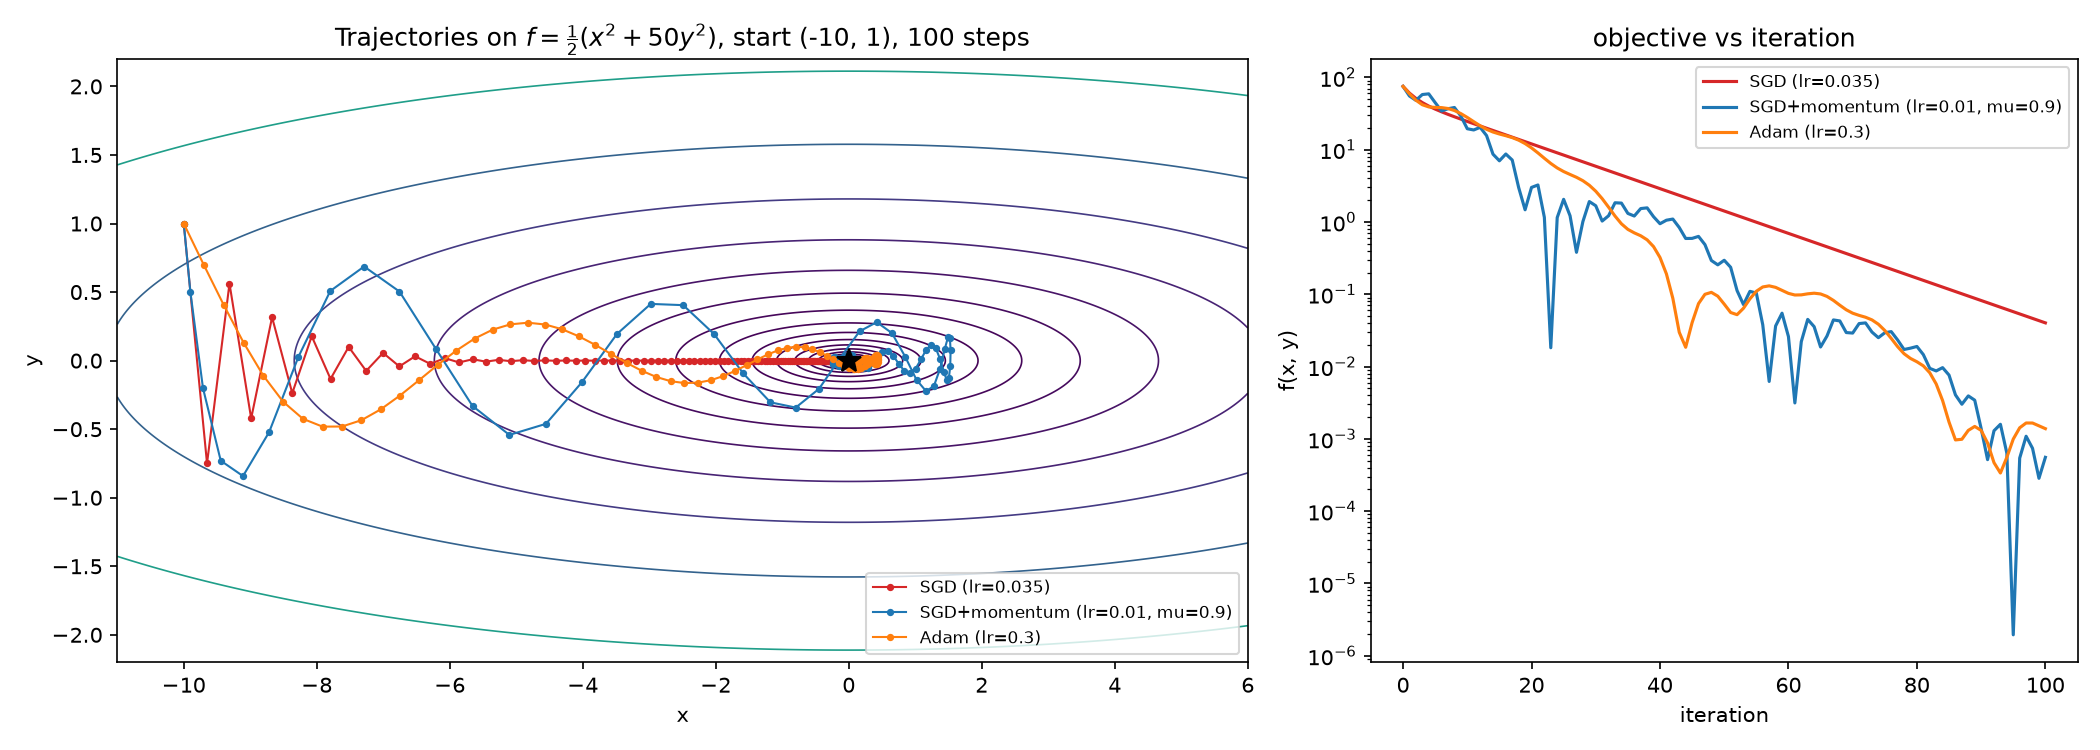

In [14]:
display(Image(filename='results/task2/quadratic_trajectories.png'))

**Discussion**

The Hessian is diag(1, 50), so the condition number is **50**: the y-direction is 50× steeper than the x-direction.

- **SGD (lr = 0.035)**
  - Gradient descent on a quadratic is stable only when lr < 2/λ_max = 2/50 = 0.04, so the steep y-direction caps the learning rate.
  - In y the per-step factor is 1 − 0.035·50 = −0.75: the sign flips every step, which is the **zig-zag** seen in the first ~15 steps, before y converges.
  - In x the factor is 1 − 0.035 = 0.965, so it only moves 3.5% closer per step and **crawls**: after 100 steps x = −10·0.965¹⁰⁰ ≈ −0.28 and f = 0.040, a straight line on the log plot.
- **SGD + momentum (lr = 0.01, μ = 0.9)**
  - Momentum accumulates the consistent gradient along x, so the effective step along the valley is about lr/(1−μ) = 0.1, much larger than plain SGD can use.
  - The alternating y-gradients cancel out in the velocity, which damps the zig-zag.
  - It overshoots and spirals around the minimum (x reaches about +1.5), so the loss curve is bumpy, but it ends **closest to the minimum (f = 5.6e-4)**.
- **Adam (lr = 0.3)**
  - Adam divides each coordinate's step by the running RMS of its gradient, so x and y get steps of similar size regardless of curvature. It therefore moves **diagonally** at first and follows a smooth path, without SGD's zig-zag.
  - Near the minimum the normalised step does not shrink with the gradient, so it oscillates on a scale set by lr and ends at f = 1.4e-3.

Momentum fixes ill-conditioning by building speed along the shallow direction, Adam by rescaling each coordinate. Both reach f ≈ 1e-3 where plain SGD is still at 4e-2.

### 2(c) Optimizers and learning rates on a small CNN

In [15]:
# Task 2(c): small CNNs used in Tasks 2(c) and 3(a)
class SmallCNN(nn.Module):
    """Task 2(c): small CNN, no batch norm (so the optimiser matters more)."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),    # 16x16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),   # 8x8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),  # 4x4
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(inplace=True),
            nn.Linear(256, num_classes))

    def forward(self, x):
        return self.net(x)


def conv_bn_relu(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


class SmallBNCNN(nn.Module):
    """Task 3(a): small CNN with batch norm and optional dropout in the head."""
    def __init__(self, dropout=0.0, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_bn_relu(3, 32), conv_bn_relu(32, 32), nn.MaxPool2d(2),
            conv_bn_relu(32, 64), conv_bn_relu(64, 64), nn.MaxPool2d(2),
            conv_bn_relu(64, 128), nn.MaxPool2d(2))
        self.head = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(256, num_classes))

    def forward(self, x):
        return self.head(self.features(x))

In [16]:
# Task 2(c): 3 optimizers x 3 learning rates, 15 epochs each (finished runs are reloaded)
# ======================= (c) =======================
print("== Task 2(c): small CNN, 3 optimisers x 3 learning rates ==")
grid = {
    "SGD": (lambda ps, lr: MySGD(ps, lr=lr), [0.01, 0.05, 0.2]),
    "SGD+momentum": (lambda ps, lr: MySGD(ps, lr=lr, momentum=0.9), [0.001, 0.01, 0.05]),
    "Adam": (lambda ps, lr: MyAdam(ps, lr=lr), [1e-4, 1e-3, 1e-2]),
}
epochs = epochs_for(args, args.epochs)
res_path = os.path.join(od, "lr_sweep.json")
results = json.load(open(res_path)) if os.path.exists(res_path) else {}
for name, (make, lrs) in grid.items():
    for lr in lrs:
        key = f"{name}@{lr:g}"
        if key in results and not args.quick:
            print("skip (already done):", key)
            continue
        set_seed(args.seed)
        model = SmallCNN().to(DEVICE)
        # constant lr and fp32 so only the optimiser differs
        H = train(model, data, epochs, make(model.parameters(), lr), bs=128,
                  amp=False, tag=key)
        results[key] = dict(opt=name, lr=lr, final_val_acc=H["val_acc"][-1],
                            best_val_acc=max(H["val_acc"]), hist=H)
        save_json(results, res_path)       # checkpoint after every run

table = [dict(optimizer=v["opt"], lr=v["lr"], final_val_acc=v["final_val_acc"],
              best_val_acc=v["best_val_acc"], diverged=v["hist"]["diverged"])
         for v in results.values()]
pd.DataFrame(table).to_csv(os.path.join(od, "lr_sweep_table.csv"), index=False)
print(pd.DataFrame(table).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
colors = dict(zip(grid, ["tab:red", "tab:blue", "tab:orange"]))
for name in grid:
    rs = sorted([v for v in results.values() if v["opt"] == name], key=lambda v: v["lr"])
    ax[0].semilogx([r["lr"] for r in rs], [r["final_val_acc"] for r in rs], "o-",
                   color=colors[name], label=name)
    best = max(rs, key=lambda r: r["final_val_acc"])
    il = best["hist"]["iter_loss"]
    ax[1].plot(np.arange(len(smooth(il))), smooth(il), color=colors[name],
               label=f"{name} (lr={best['lr']:g})")
ax[0].set(xlabel="learning rate (log scale)", ylabel=f"validation accuracy after {epochs} epochs",
          title="Learning-rate sensitivity")
ax[0].grid(True, which="both", alpha=0.3)
ax[0].legend()
ax[1].set(xlabel="iteration", ylabel="training loss (moving avg 50)",
          title="Training loss at the best learning rate")
ax[1].legend()
fig.tight_layout()
fig.savefig(os.path.join(od, "lr_sweep.png"), dpi=150)
plt.close(fig)
print("Task 2 done ->", od)

== Task 2(c): small CNN, 3 optimisers x 3 learning rates ==
skip (already done): SGD@0.01
skip (already done): SGD@0.05
skip (already done): SGD@0.2
skip (already done): SGD+momentum@0.001
skip (already done): SGD+momentum@0.01
skip (already done): SGD+momentum@0.05
skip (already done): Adam@0.0001
skip (already done): Adam@0.001
skip (already done): Adam@0.01
   optimizer     lr  final_val_acc  best_val_acc  diverged
         SGD 0.0100         0.6192        0.6192     False
         SGD 0.0500         0.7502        0.7502     False
         SGD 0.2000         0.7346        0.7346     False
SGD+momentum 0.0010         0.6274        0.6274     False
SGD+momentum 0.0100         0.7432        0.7538     False
SGD+momentum 0.0500         0.6772        0.7288     False
        Adam 0.0001         0.6656        0.6790     False
        Adam 0.0010         0.7476        0.7566     False
        Adam 0.0100         0.0942        0.1064     False
Task 2 done -> results/task2


In [17]:
print_log(results, every=3)

[SGD@0.01] ep   3/15 loss 1.7777 train_acc 0.3612 val_acc 0.3666
[SGD@0.01] ep   6/15 loss 1.4360 train_acc 0.4855 val_acc 0.4900
[SGD@0.01] ep   9/15 loss 1.2735 train_acc 0.5481 val_acc 0.5434
[SGD@0.01] ep  12/15 loss 1.1466 train_acc 0.5971 val_acc 0.5694
[SGD@0.01] ep  15/15 loss 1.0333 train_acc 0.6376 val_acc 0.6192
[SGD@0.05] ep   3/15 loss 1.2929 train_acc 0.5371 val_acc 0.5282
[SGD@0.05] ep   6/15 loss 0.9143 train_acc 0.6792 val_acc 0.6778
[SGD@0.05] ep   9/15 loss 0.6855 train_acc 0.7605 val_acc 0.7082
[SGD@0.05] ep  12/15 loss 0.4976 train_acc 0.8280 val_acc 0.7234
[SGD@0.05] ep  15/15 loss 0.3332 train_acc 0.8847 val_acc 0.7502
[SGD@0.2] ep   3/15 loss 1.0020 train_acc 0.6483 val_acc 0.6108
[SGD@0.2] ep   6/15 loss 0.5736 train_acc 0.7994 val_acc 0.7180
[SGD@0.2] ep   9/15 loss 0.2890 train_acc 0.8981 val_acc 0.7244
[SGD@0.2] ep  12/15 loss 0.1515 train_acc 0.9488 val_acc 0.6866
[SGD@0.2] ep  15/15 loss 0.0934 train_acc 0.9689 val_acc 0.7346
[SGD+momentum@0.001] ep   3/15

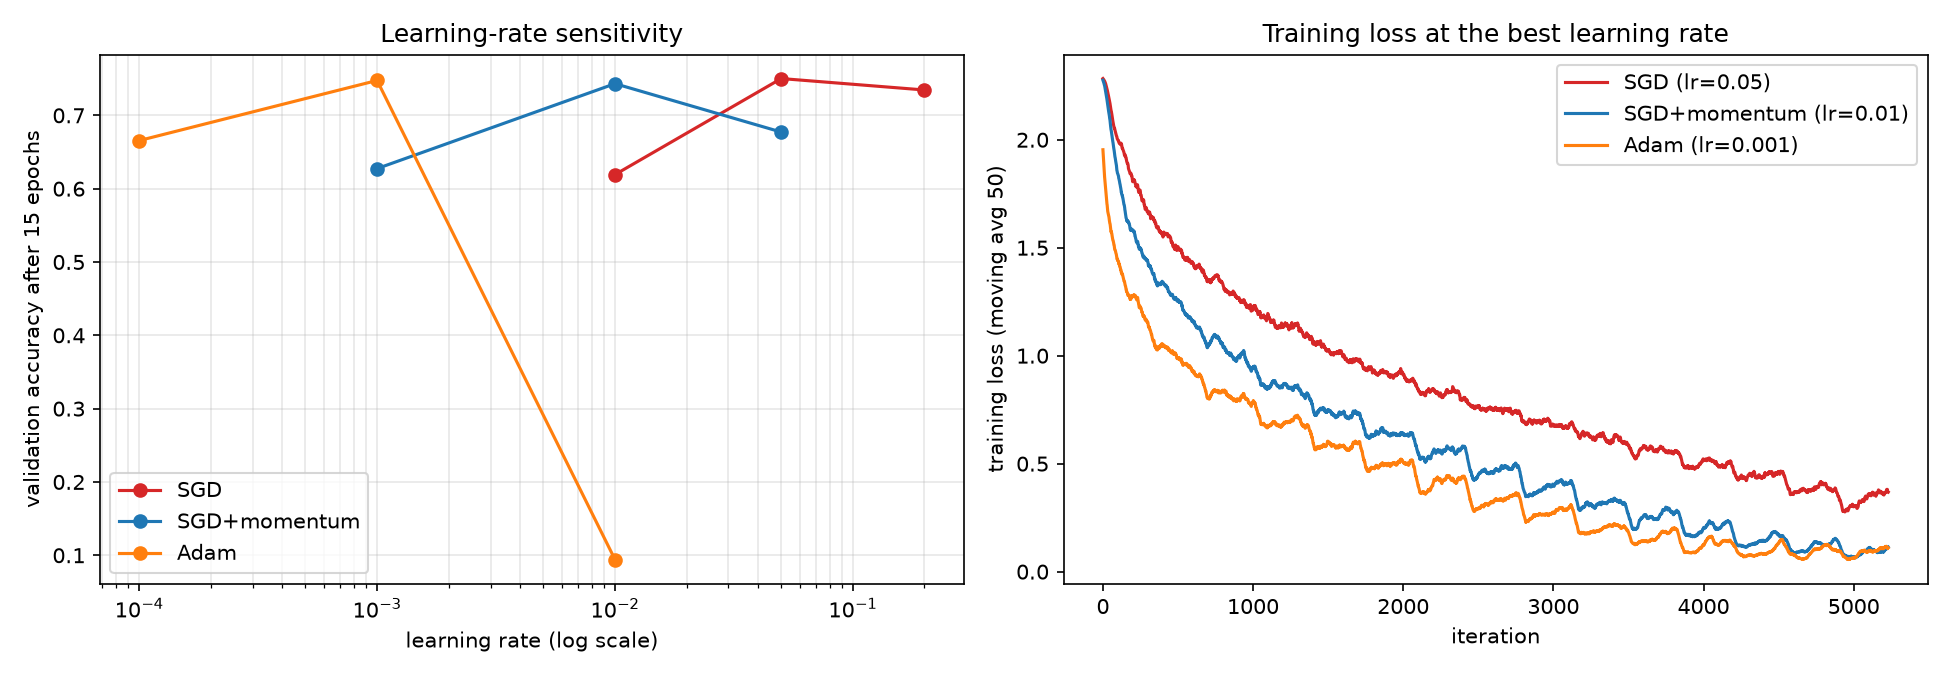

In [18]:
display(Image(filename='results/task2/lr_sweep.png'))

**Discussion**

Best final validation accuracy after 15 epochs: **SGD 75.0% (lr 0.05)**, **Adam 74.8% (lr 1e-3, best 75.7%)**, **SGD + momentum 74.3% (lr 0.01, best 75.4%)**. At their best learning rate all three end within about 1 point of each other.

**Sensitivity to the learning rate**
- **Adam is the most sensitive.** At lr = 1e-2 it never learns: from the first epoch the loss is stuck at 2.303 = ln 10 and accuracy is 10% (chance). The large early steps most likely pushed the ReLU units into the dead region, so no gradient flows. It is not flagged as diverged because the loss never becomes NaN. At 1e-4 it is too slow (66.6%).
- **SGD + momentum:** with μ = 0.9 the effective step is about 10 × lr. At 0.05 (effective 0.5) the training loss stops falling after epoch 9 and rises again, and validation accuracy drops from 72.9% to 67.7%. At 0.001 it is too slow (62.7%).
- **Plain SGD is the least sensitive in this grid:** 0.05 and 0.2 differ by only 1.6 points, and only 0.01 is clearly too slow (61.9%).

**Speed at the best learning rate.** After epoch 1 the training loss is 1.42 for Adam, 1.76 for momentum and 1.94 for SGD, so Adam converges fastest, then momentum, then SGD.

**Generalisation.** Faster optimisation did not mean better generalisation. Adam and momentum reach ~97% train accuracy, and their validation loss is lowest around epoch 6 to 7 (0.72 / 0.76) and then rises to 1.31 / 1.15, i.e. they overfit. Plain SGD at 0.05 is at 88% train accuracy with its validation loss still falling (0.81), giving the smallest train/val gap.

Overall, each optimizer only works within about one order of magnitude of learning rate, so tuning the learning rate matters more than the choice of optimizer.

## Task 3: Regularization and residual connections

### 3(a) Regularization with 5k training images

In [19]:
# Task 3(a): regularisation on 5k training images (finished runs are reloaded)
CONFIGS = {
    "baseline":     dict(),
    "weight_decay": dict(wd=5e-4),
    "dropout":      dict(dropout=0.5),
    "flip+crop":    dict(aug=["flip", "crop"]),
    "cutout":       dict(aug=["cutout"]),
    "mixup":        dict(mixup=0.4),
    "all":          dict(wd=5e-4, dropout=0.5, aug=["flip", "crop", "cutout"], mixup=0.4),
}


def main():
    p = base_parser("Task 3a")
    p.add_argument("--epochs", type=int, default=100)
    p.add_argument("--lr", type=float, default=0.05)
    p.add_argument("--n-train", type=int, default=5000)
    args = p.parse_args()
    set_seed(args.seed)
    od = out_dir(args, "task3a")
    data = load_cifar10(args)
    n = min(args.n_train, len(data["xtr"]))
    xs, ys = data["xtr"][:n], data["ytr"][:n]       # 5k images (split is random)
    epochs = epochs_for(args, args.epochs)
    amp = not args.no_amp

    res_path = os.path.join(od, "results.json")
    results = json.load(open(res_path)) if os.path.exists(res_path) else {}
    for name, cfg in CONFIGS.items():
        if name in results and not args.quick:
            print("skip (already done):", name)
            continue
        set_seed(args.seed)
        model = SmallBNCNN(dropout=cfg.get("dropout", 0.0)).to(DEVICE)
        opt = MySGD(model.parameters(), lr=args.lr, momentum=0.9, weight_decay=cfg.get("wd", 0.0))
        steps = epochs * math.ceil(n / 128)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
        H = train(model, data, epochs, opt, sched, bs=128, aug=make_aug(cfg.get("aug")),
                  mixup_alpha=cfg.get("mixup", 0.0), amp=amp, xtr=xs, ytr=ys,
                  clean_train_eval=True, tag=name)
        results[name] = dict(cfg=cfg, hist=H)
        save_json(results, res_path)

    import pandas as pd
    rows = []
    for name, r in results.items():
        H = r["hist"]
        tr, va = H["train_acc_clean"][-1], H["val_acc"][-1]
        rows.append(dict(method=name, train_acc=round(tr, 4), val_acc=round(va, 4),
                         gap=round(tr - va, 4), best_val_acc=round(max(H["val_acc"]), 4)))
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(od, "table.csv"), index=False)
    print(df.to_string(index=False))

    names = list(results)
    cols = 4
    rws = math.ceil(len(names) / cols)
    fig, axs = plt.subplots(rws, cols, figsize=(4 * cols, 3.2 * rws), sharey=True)
    for a, name in zip(axs.flat, names):
        H = results[name]["hist"]
        e = np.arange(1, len(H["val_acc"]) + 1)
        a.plot(e, H["train_acc_clean"], label="train (clean)")
        a.plot(e, H["val_acc"], label="validation")
        a.set_title(f"{name}: gap {H['train_acc_clean'][-1] - H['val_acc'][-1]:.3f}")
        a.set_xlabel("epoch")
        a.grid(alpha=0.3)
    for a in list(axs.flat)[len(names):]:
        a.axis("off")
    axs.flat[0].set_ylabel("accuracy")
    axs.flat[0].legend()
    fig.suptitle("Task 3(a): train vs validation accuracy, 5k training images")
    fig.tight_layout()
    fig.savefig(os.path.join(od, "curves_grid.png"), dpi=150)
    plt.close(fig)

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for name in names:
        H = results[name]["hist"]
        e = np.arange(1, len(H["val_acc"]) + 1)
        ax[0].plot(e, H["val_acc"], label=name)
        ax[1].plot(e, H["val_loss"], label=name)
    ax[0].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy")
    ax[1].set(xlabel="epoch", ylabel="validation loss", title="Validation loss")
    ax[0].legend(fontsize=8)
    ax[0].grid(alpha=0.3)
    ax[1].grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(od, "val_curves.png"), dpi=150)
    plt.close(fig)
    print("Task 3a done ->", od)


sys.argv = ['task3a'] + ARGV
main()

skip (already done): baseline
skip (already done): weight_decay
skip (already done): dropout
skip (already done): flip+crop
skip (already done): cutout
skip (already done): mixup
skip (already done): all
      method  train_acc  val_acc    gap  best_val_acc
    baseline     1.0000   0.6686 0.3314        0.6752
weight_decay     1.0000   0.6732 0.3268        0.6754
     dropout     0.9988   0.7122 0.2866        0.7170
   flip+crop     0.9922   0.7660 0.2262        0.7704
      cutout     0.9998   0.6880 0.3118        0.6938
       mixup     1.0000   0.6534 0.3466        0.6644
         all     0.7692   0.7002 0.0690        0.7036


Task 3a done -> results/task3a


In [20]:
results_3a = json.load(open('results/task3a/results.json'))
print_log(results_3a, every=20)

[baseline] ep  20/100 loss 0.2912 train_acc 0.8986 val_acc 0.6042
[baseline] ep  40/100 loss 0.0039 train_acc 0.9996 val_acc 0.6686
[baseline] ep  60/100 loss 0.0024 train_acc 1.0000 val_acc 0.6714
[baseline] ep  80/100 loss 0.0023 train_acc 1.0000 val_acc 0.6656
[baseline] ep 100/100 loss 0.0012 train_acc 1.0000 val_acc 0.6686
[weight_decay] ep  20/100 loss 0.0887 train_acc 0.9762 val_acc 0.6352
[weight_decay] ep  40/100 loss 0.0055 train_acc 0.9998 val_acc 0.6706
[weight_decay] ep  60/100 loss 0.0021 train_acc 1.0000 val_acc 0.6726
[weight_decay] ep  80/100 loss 0.0033 train_acc 1.0000 val_acc 0.6730
[weight_decay] ep 100/100 loss 0.0027 train_acc 1.0000 val_acc 0.6732
[dropout] ep  20/100 loss 1.2816 train_acc 0.5340 val_acc 0.5276
[dropout] ep  40/100 loss 0.7550 train_acc 0.7308 val_acc 0.6498
[dropout] ep  60/100 loss 0.2979 train_acc 0.8974 val_acc 0.6874
[dropout] ep  80/100 loss 0.1527 train_acc 0.9540 val_acc 0.7074
[dropout] ep 100/100 loss 0.1094 train_acc 0.9670 val_acc 0.

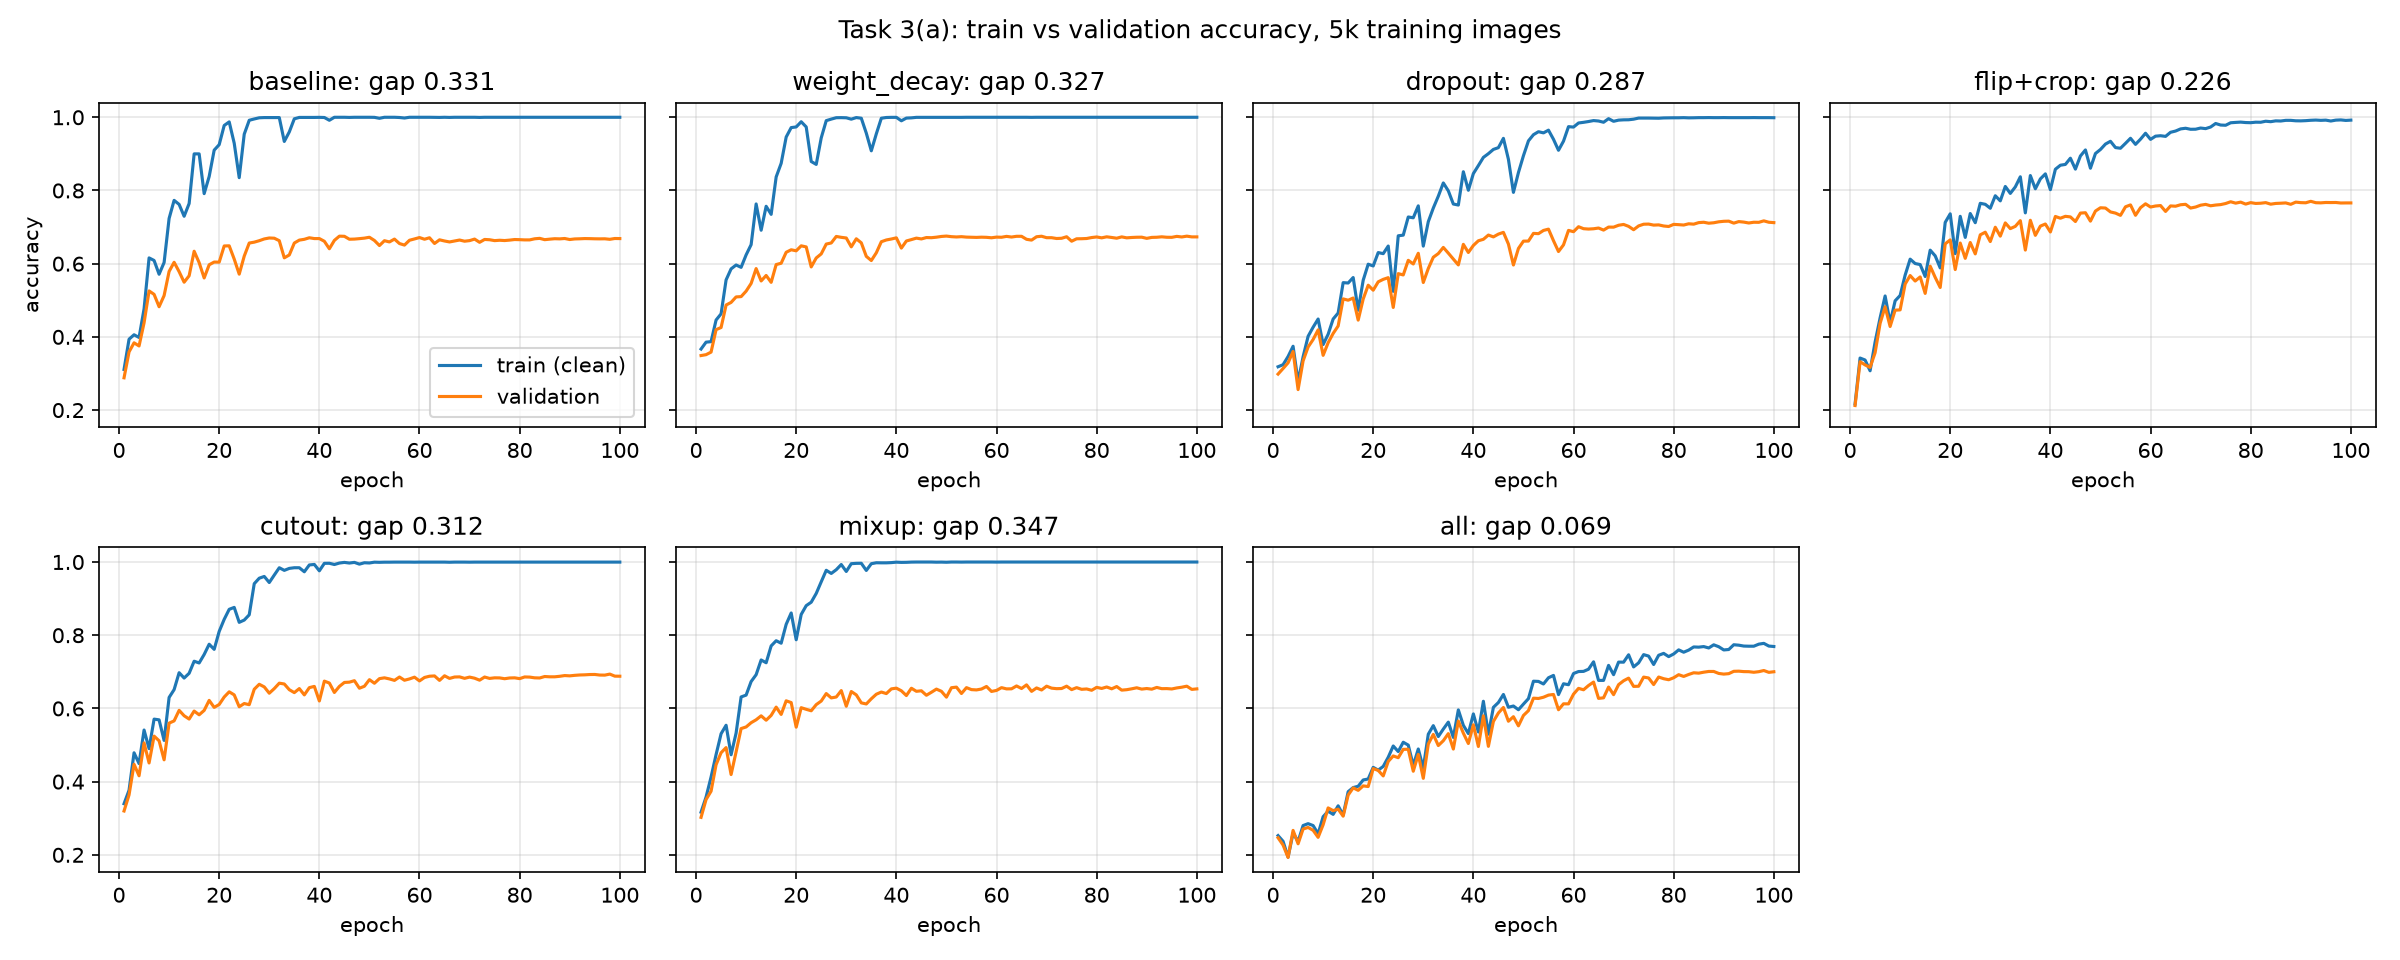

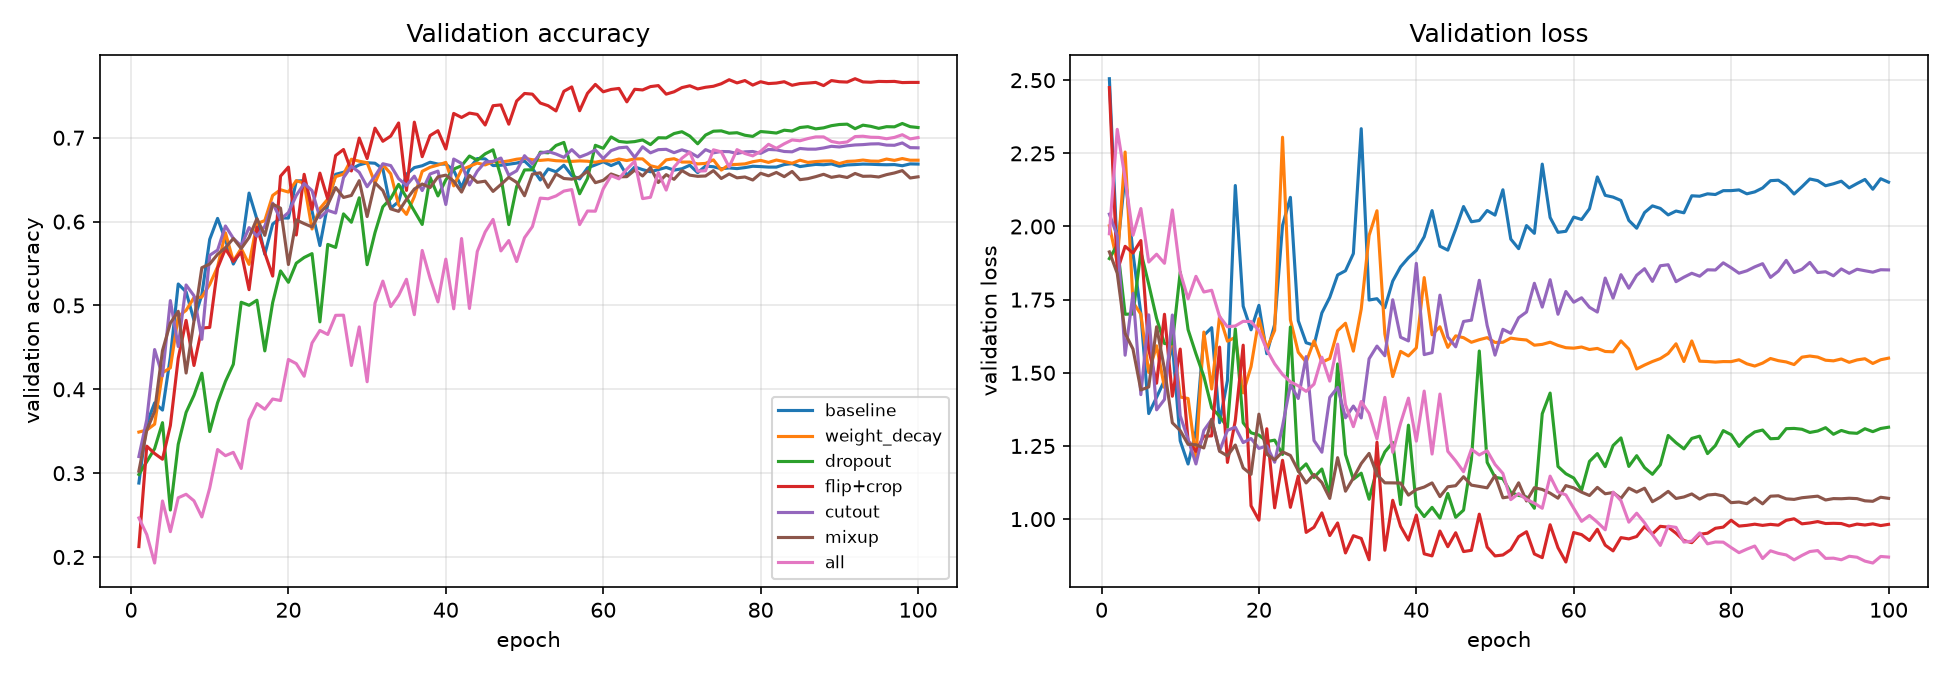

In [21]:
display(Image(filename='results/task3a/curves_grid.png'))
display(Image(filename='results/task3a/val_curves.png'))

**Discussion**

With only 5k training images the **baseline memorises the training set**: clean train accuracy is 100% from about epoch 29, but validation accuracy is only **66.9%**, a gap of 0.33.

| Method | Train acc (clean) | Val acc | Gap | Change in val acc |
|---|---|---|---|---|
| Baseline | 100% | 66.9% | 0.33 | – |
| Flip + crop | 99.2% | **76.6%** | 0.23 | **+9.7** |
| Dropout 0.5 | 99.9% | 71.2% | 0.29 | +4.4 |
| All combined | 76.9% | 70.0% | **0.07** | +3.2 |
| Cutout | 100% | 68.8% | 0.31 | +1.9 |
| Weight decay | 100% | 67.3% | 0.33 | +0.5 |
| Mixup | 100% | 65.3% | 0.35 | −1.5 |

- **Flip + crop helps most**: it creates realistic new images (a mirrored or shifted car is still a car), so the model sees more varied data. It shrinks the gap and gives the largest validation gain.
- **Dropout** slows memorisation (train accuracy rises much more gradually) and adds 4.4 points.
- **Cutout and weight decay barely help** here. Cutout alone still lets the network reach 100% clean train accuracy. With batch norm, weight decay mostly changes the effective learning rate of the scale-invariant convolution weights rather than limiting capacity.
- **Mixup**: the accuracy measured on the mixed training batches is low (~46%) because the targets are soft blends of two labels, which is why train accuracy here is measured on clean images. On clean images it still reaches 100%, so mixup did not stop memorisation, and validation accuracy is slightly lower than the baseline.
- **All combined** gives by far the smallest gap (0.07), but only because train accuracy drops to 77%: the model now **underfits**. Its validation accuracy is 6.6 points below flip + crop alone.

The effects are **not additive**: stacking every regulariser was worse than the best single one. A small gap is not the goal by itself; the aim is the highest validation accuracy, which needs the right amount of regularisation.

### 3(b) Plain vs residual networks

In [22]:
# Task 3(b): CIFAR-style plain / residual networks of depth 6n + 2 (option-A shortcut)
class ShortcutA(nn.Module):
    """Parameter-free shortcut (option A of He et al. 2016): subsample by the
    stride and zero-pad the extra channels. Using it means the plain and the
    residual networks have exactly the same parameters."""
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.stride, self.extra = stride, cout - cin

    def forward(self, x):
        if self.stride > 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra > 0:
            x = F.pad(x, (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))
        return x


class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.residual = residual
        self.shortcut = ShortcutA(cin, cout, stride)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:                 # <-- the ONLY difference plain/residual
            out = out + self.shortcut(x)
        return F.relu(out)


class CifarResNet(nn.Module):
    """Depth 6n+2: conv -> 3 stages of n blocks (16/32/64 ch) -> GAP -> FC."""
    def __init__(self, depth, residual=True, widths=(16, 32, 64), num_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0, "depth must be 6n+2"
        n = (depth - 2) // 6
        self.conv = nn.Conv2d(3, widths[0], 3, 1, 1, bias=False)
        self.bn = nn.BatchNorm2d(widths[0])
        blocks, cin = [], widths[0]
        for s, w in enumerate(widths):
            for j in range(n):
                stride = 2 if (s > 0 and j == 0) else 1
                blocks.append(BasicBlock(cin, w, stride, residual))
                cin = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(widths[-1], num_classes)
        for m in self.modules():          # Kaiming (He) initialisation
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = self.blocks(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

In [23]:
# Task 3(b): depths 8, 20, 56, plain vs residual, lr 0.1 (finished runs are reloaded)
def main():
    p = base_parser("Task 3b")
    p.add_argument("--epochs", type=int, default=30)
    p.add_argument("--depths", type=int, nargs="+", default=[8, 20, 56])
    p.add_argument("--lr", type=float, default=0.1)
    args = p.parse_args()
    set_seed(args.seed)
    od = out_dir(args, "task3b")
    data = load_cifar10(args)
    epochs = epochs_for(args, args.epochs)
    amp = not args.no_amp
    aug = make_aug(["flip", "crop"])           # standard CIFAR augmentation

    res_path = os.path.join(od, "results.json")
    results = json.load(open(res_path)) if os.path.exists(res_path) else {}
    for depth in args.depths:
        for residual in [False, True]:
            key = f"{'resnet' if residual else 'plain'}-{depth}"
            if key in results and not args.quick:
                print("skip (already done):", key)
                continue
            set_seed(args.seed)
            model = CifarResNet(depth, residual=residual).to(DEVICE)
            n_params = count_params(model)
            print(f"{key}: {n_params:,} parameters")
            opt = MySGD(model.parameters(), lr=args.lr, momentum=0.9, weight_decay=1e-4)
            it = math.ceil(len(data["xtr"]) / 128)
            # step decay /10 at 50% and 75% of training (as in He et al.)
            sched = torch.optim.lr_scheduler.MultiStepLR(
                opt, milestones=[int(0.5 * epochs) * it, int(0.75 * epochs) * it], gamma=0.1)
            H = train(model, data, epochs, opt, sched, bs=128, aug=aug, amp=amp, tag=key)
            results[key] = dict(depth=depth, residual=residual, params=n_params, hist=H)
            save_json(results, res_path)

    import pandas as pd
    rows = [dict(model=k, params=v["params"], final_train_loss=round(v["hist"]["train_loss"][-1], 4),
                 final_train_acc=round(v["hist"]["train_acc"][-1], 4),
                 final_val_acc=round(v["hist"]["val_acc"][-1], 4)) for k, v in results.items()]
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(od, "table.csv"), index=False)
    print(df.to_string(index=False))

    depths = sorted({v["depth"] for v in results.values()})
    colors = dict(zip(depths, ["tab:green", "tab:blue", "tab:red", "tab:purple", "tab:brown"]))
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    for k, v in results.items():
        H, d = v["hist"], v["depth"]
        ls = "-" if v["residual"] else "--"
        e = np.arange(1, len(H["train_loss"]) + 1)
        ax[0].plot(e, H["train_loss"], ls, color=colors[d], label=k)
        ax[1].plot(np.arange(len(smooth(H["iter_loss"], 100))), smooth(H["iter_loss"], 100),
                   ls, color=colors[d], label=k, lw=1)
        ax[2].plot(e, [1 - a for a in H["val_acc"]], ls, color=colors[d], label=k)
    ax[0].set(xlabel="epoch", ylabel="training loss (epoch mean)", yscale="log",
              title="Training loss: plain (dashed) vs residual (solid)")
    ax[1].set(xlabel="iteration", ylabel="training loss (moving avg 100)", yscale="log",
              title="Training loss per iteration")
    ax[2].set(xlabel="epoch", ylabel="validation error", title="Validation error")
    for a in ax:
        a.grid(True, which="both", alpha=0.3)
        a.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(od, "plain_vs_residual.png"), dpi=150)
    plt.close(fig)
    print("Task 3b done ->", od)


sys.argv = ['task3b'] + ARGV
main()

skip (already done): plain-8
skip (already done): resnet-8
skip (already done): plain-20
skip (already done): resnet-20
skip (already done): plain-56
skip (already done): resnet-56
    model  params  final_train_loss  final_train_acc  final_val_acc
  plain-8   75290            0.4097           0.8592         0.8424
 resnet-8   75290            0.4349           0.8504         0.8362
 plain-20  269722            0.2893           0.8998         0.8690
resnet-20  269722            0.3027           0.8958         0.8686
 plain-56  853018               NaN           0.0990         0.1002
resnet-56  853018            0.4002           0.8595         0.8252


Task 3b done -> results/task3b


In [24]:
results_3b = json.load(open('results/task3b/results.json'))
print_log(results_3b, every=5)

[plain-8] ep   5/30 loss 0.8302 train_acc 0.7066 val_acc 0.7104
[plain-8] ep  10/30 loss 0.6400 train_acc 0.7770 val_acc 0.7516
[plain-8] ep  15/30 loss 0.5631 train_acc 0.8039 val_acc 0.7850
[plain-8] ep  20/30 loss 0.4360 train_acc 0.8494 val_acc 0.8352
[plain-8] ep  25/30 loss 0.4189 train_acc 0.8560 val_acc 0.8424
[plain-8] ep  30/30 loss 0.4097 train_acc 0.8592 val_acc 0.8424
[resnet-8] ep   5/30 loss 0.9110 train_acc 0.6782 val_acc 0.6672
[resnet-8] ep  10/30 loss 0.6898 train_acc 0.7615 val_acc 0.7256
[resnet-8] ep  15/30 loss 0.5944 train_acc 0.7953 val_acc 0.7676
[resnet-8] ep  20/30 loss 0.4611 train_acc 0.8393 val_acc 0.8308
[resnet-8] ep  25/30 loss 0.4410 train_acc 0.8492 val_acc 0.8366
[resnet-8] ep  30/30 loss 0.4349 train_acc 0.8504 val_acc 0.8362
[plain-20] ep   5/30 loss 0.9237 train_acc 0.6734 val_acc 0.6992
[plain-20] ep  10/30 loss 0.6121 train_acc 0.7881 val_acc 0.7898
[plain-20] ep  15/30 loss 0.5056 train_acc 0.8262 val_acc 0.8150
[plain-20] ep  20/30 loss 0.328

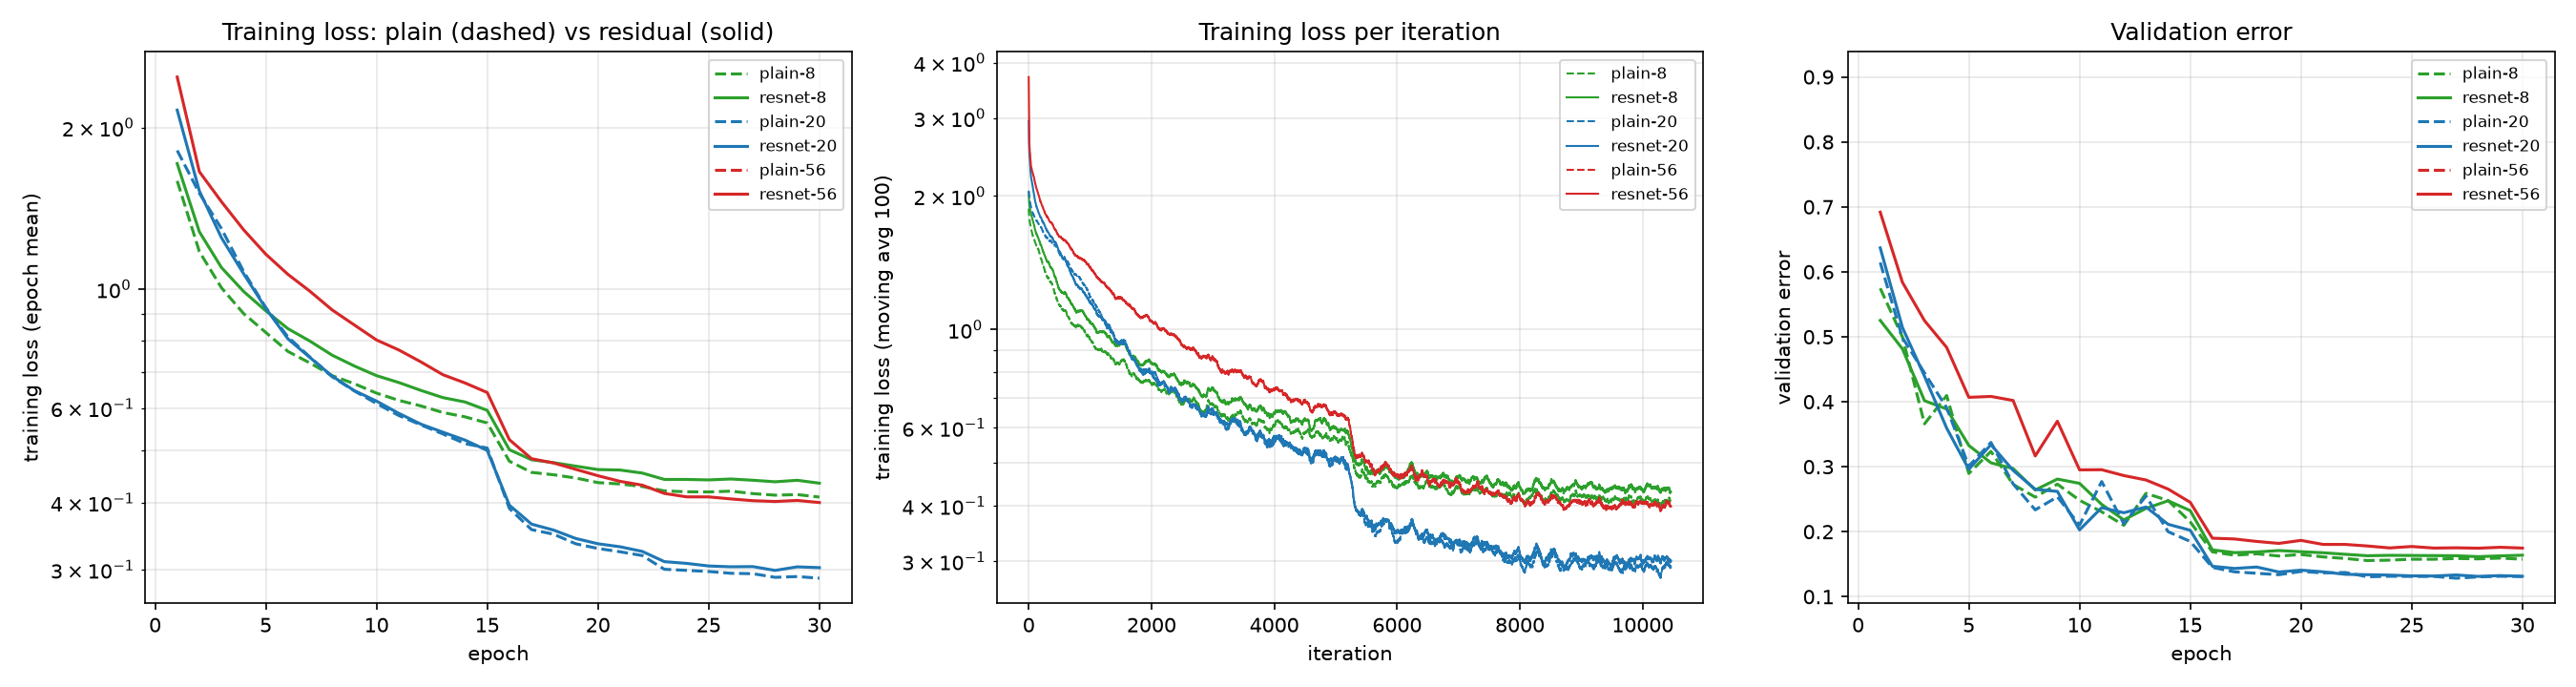

In [25]:
display(Image(filename='results/task3b/plain_vs_residual.png'))

#### Supplementary: depth 56 at lr = 0.01
Plain-56 diverged at lr = 0.1, so both depth-56 networks were rerun at lr = 0.01 (everything else identical).

In [26]:
sys.argv = ['task3b', '--data', DATA, '--out', 'results_3b_lr001', '--depths', '56', '--lr', '0.01']
main()
print_log(json.load(open('results_3b_lr001/task3b/results.json')), every=5)

skip (already done): plain-56
skip (already done): resnet-56
    model  params  final_train_loss  final_train_acc  final_val_acc
 plain-56  853018            1.4959           0.4507         0.4674
resnet-56  853018            0.3379           0.8832         0.8400


Task 3b done -> results_3b_lr001/task3b
[plain-56] ep   5/30 loss 1.9074 train_acc 0.2621 val_acc 0.2578
[plain-56] ep  10/30 loss 1.7326 train_acc 0.3461 val_acc 0.3758
[plain-56] ep  15/30 loss 1.6077 train_acc 0.4036 val_acc 0.4172
[plain-56] ep  20/30 loss 1.5166 train_acc 0.4417 val_acc 0.4520
[plain-56] ep  25/30 loss 1.4983 train_acc 0.4509 val_acc 0.4628
[plain-56] ep  30/30 loss 1.4959 train_acc 0.4507 val_acc 0.4674
[resnet-56] ep   5/30 loss 0.9416 train_acc 0.6672 val_acc 0.6572
[resnet-56] ep  10/30 loss 0.6157 train_acc 0.7842 val_acc 0.7666
[resnet-56] ep  15/30 loss 0.4794 train_acc 0.8303 val_acc 0.7920
[resnet-56] ep  20/30 loss 0.3640 train_acc 0.8742 val_acc 0.8358
[resnet-56] ep  25/30 loss 0.3477 train_acc 0.8786 val_acc 0.8416
[resnet-56] ep  30/30 loss 0.3379 train_acc 0.8832 val_acc 0.8400


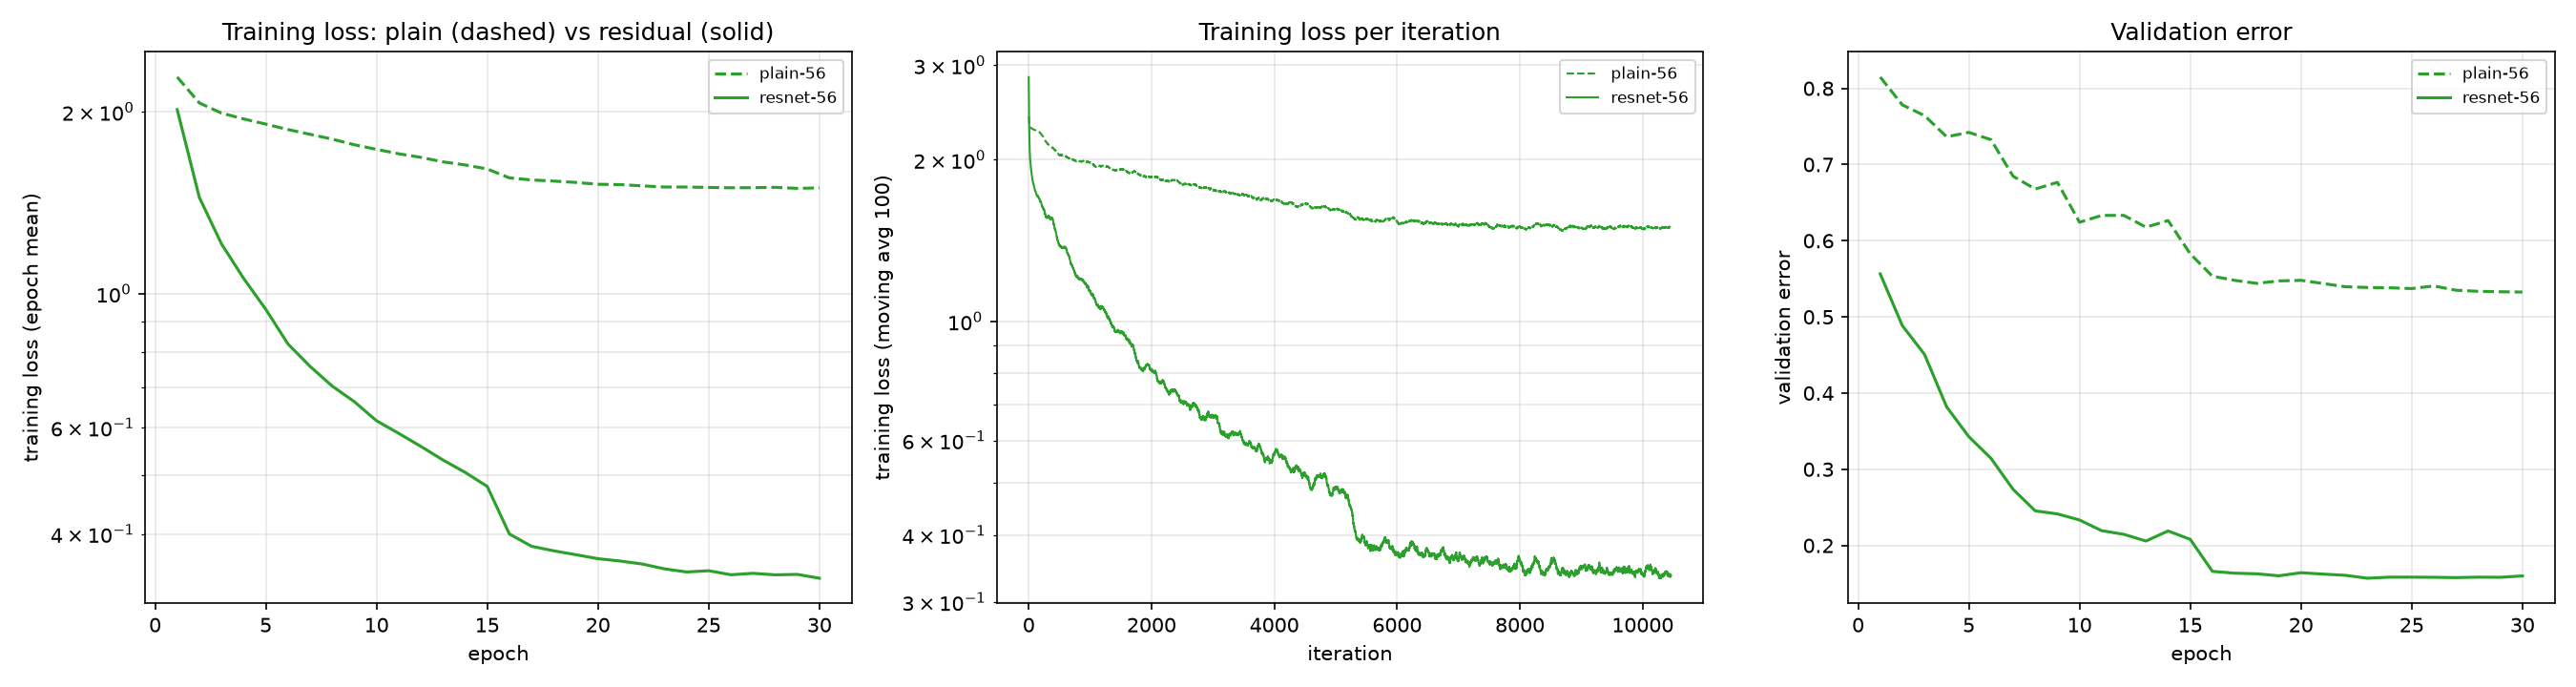

In [27]:
display(Image(filename='results/task3b_lr001/plain_vs_residual.png'))

**Discussion**

Main run (lr = 0.1, 30 epochs, flip + crop augmentation; plain and residual nets have *identical* parameter counts because the option-A shortcut has no parameters):

| Depth | Plain: train loss / val acc | Residual: train loss / val acc |
|---|---|---|
| 8 | 0.410 / 84.2% | 0.435 / 83.6% |
| 20 | 0.289 / 86.9% | 0.303 / 86.9% |
| 56 | **NaN (diverged in epoch 1)** / 10.0% | 0.400 / 82.5% |

- **Depth 8 and 20:** plain and residual are essentially the same. Shallow networks with batch norm are easy to optimise with or without shortcuts, and going from 8 to 20 layers lowers the training loss for both.
- **Depth 56 at lr 0.1:** the plain network's loss became NaN in the first epoch, so training stopped and it stayed at chance (10%). The residual network with exactly the same weights' shapes, initialisation and learning rate trained normally. This is already a sign of how badly conditioned the deep plain network is: the gradient through 56 stacked layers is unstable enough that lr = 0.1 blows it up.

**Supplementary run (depth 56 only, lr = 0.01)**, added so that the plain-56 network can train without diverging (He et al. also used a smaller learning rate to start their deepest networks):

| Model | Train loss | Train acc | Val acc |
|---|---|---|---|
| plain-56 (lr 0.01) | **1.496** | 45.1% | 46.7% |
| resnet-56 (lr 0.01) | 0.338 | 88.3% | 84.0% |
| plain-20 (lr 0.1, main run) | 0.289 | 90.0% | 86.9% |

- **This is the degradation problem.** Plain-56 has a far *higher training loss* (1.50) than plain-20 (0.29), and it is still stuck at 1.50 after the learning rate decays. Because it is the *training* loss that is worse, this is not overfitting; the deeper plain network is simply harder to optimise, even though it could in principle copy plain-20 and set the extra 36 layers to the identity.
- At the same learning rate, **resnet-56 trains without difficulty** (train loss 0.34, val 84.0%), so the shortcut is the only difference that matters:
  - each block only needs to learn a residual F(x) on top of the identity, so a near-identity mapping is easy to represent (F ≈ 0), and
  - the identity path gives gradients a direct route to the early layers, so they do not have to pass through every convolution.
- One caveat: in our 30-epoch budget resnet-56 (82.5% at lr 0.1, 84.0% at lr 0.01) does not beat resnet-20 (86.9%). The shortcut makes the deep network *trainable*, but 853k parameters at depth 56 need a longer schedule than 30 epochs to pay off; in He et al. (160+ epochs) the deeper ResNets were better.

## Task 4: Best CNN (≤ 500k parameters, ≤ 20 epochs)

In [28]:
# Task 4: scaled-down ResNet-9
class Residual(nn.Module):
    def __init__(self, c, shortcut=True):
        super().__init__()
        self.f = nn.Sequential(conv_bn_relu(c, c), conv_bn_relu(c, c))
        self.shortcut = shortcut

    def forward(self, x):
        return x + self.f(x) if self.shortcut else self.f(x)


class Scale(nn.Module):
    def __init__(self, s):
        super().__init__()
        self.s = s

    def forward(self, x):
        return x * self.s


class Task4Net(nn.Module):
    """ResNet-9-style network scaled down to < 500k parameters."""
    def __init__(self, c=(32, 64, 96, 192), shortcut=True, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            conv_bn_relu(3, c[0]),
            conv_bn_relu(c[0], c[1]), nn.MaxPool2d(2), Residual(c[1], shortcut),   # 16x16
            conv_bn_relu(c[1], c[2]), nn.MaxPool2d(2), Residual(c[2], shortcut),   # 8x8
            conv_bn_relu(c[2], c[3]), nn.MaxPool2d(2),                              # 4x4
            nn.AdaptiveMaxPool2d(1), nn.Flatten(),
            nn.Linear(c[3], num_classes, bias=False), Scale(0.125))

    def forward(self, x):
        return self.net(x)

In [29]:
# Task 4: ablations chosen on validation; test set evaluated once (guard file)
MAX_PARAMS, MAX_EPOCHS = 500_000, 20

FULL = dict(shortcut=True, aug=["flip", "crop", "cutout"], cutout_size=8,
            opt="sgd", lr=0.1, wd=5e-4, label_smoothing=0.1, bs=256)
ABLATIONS = {                                  # each changes ONE design choice
    "full":              {},
    "no_shortcut":       dict(shortcut=False),
    "no_augmentation":   dict(aug=[]),
    "flip_crop_only":    dict(aug=["flip", "crop"]),
    "no_weight_decay":   dict(wd=0.0),
    "adamw_instead_sgd": dict(opt="adamw", lr=2e-3, wd=5e-2),
    "no_label_smoothing": dict(label_smoothing=0.0),
}


def one_cycle(opt, total_steps, warm=0.25):
    """Linear warm-up to the peak lr for 25% of the steps, then linear decay to 0."""
    w = int(warm * total_steps)
    f = lambda s: (s + 1) / w if s < w else max(0.0, (total_steps - s) / (total_steps - w))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)


def build(cfg):
    model = Task4Net(shortcut=cfg["shortcut"]).to(DEVICE).to(memory_format=torch.channels_last)
    n = count_params(model)
    assert n <= MAX_PARAMS, f"{n} parameters > {MAX_PARAMS}"
    if cfg["opt"] == "sgd":
        opt = MySGD(model.parameters(), lr=cfg["lr"], momentum=0.9, nesterov=True,
                    weight_decay=cfg["wd"])
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    return model, opt, n


def main():
    p = base_parser("Task 4")
    p.add_argument("--epochs", type=int, default=20)
    p.add_argument("--runs", nargs="+", default=list(ABLATIONS))
    p.add_argument("--evaluate-test", action="store_true",
                   help="after all ablations, evaluate the best one on the test set ONCE")
    args = p.parse_args()
    assert args.epochs <= MAX_EPOCHS
    set_seed(args.seed)
    od = out_dir(args, "task4")
    data = load_cifar10(args, load_test=args.evaluate_test)
    epochs = epochs_for(args, args.epochs)
    amp = not args.no_amp

    res_path = os.path.join(od, "results.json")
    results = json.load(open(res_path)) if os.path.exists(res_path) else {}
    for name in args.runs:
        if name in results and not args.quick:
            print("skip (already done):", name)
            continue
        cfg = {**FULL, **ABLATIONS[name]}
        set_seed(args.seed)
        model, opt, n = build(cfg)
        print(f"{name}: {n:,} params, cfg={cfg}")
        steps = epochs * math.ceil(len(data["xtr"]) / cfg["bs"])
        t0 = time.time()
        H = train(model, data, epochs, opt, one_cycle(opt, steps), bs=cfg["bs"],
                  aug=make_aug(cfg["aug"], cfg["cutout_size"]),
                  label_smoothing=cfg["label_smoothing"], amp=amp, tag=name)
        torch.save(model.state_dict(), os.path.join(od, f"{name}.pt"))
        results[name] = dict(cfg=cfg, params=n, train_time_s=time.time() - t0,
                             final_val_acc=H["val_acc"][-1], hist=H)
        save_json(results, res_path)

    import pandas as pd
    rows = [dict(run=k, params=v["params"], final_val_acc=round(v["final_val_acc"], 4),
                 delta_vs_full=round(v["final_val_acc"] - results.get("full", v)["final_val_acc"], 4),
                 minutes=round(v["train_time_s"] / 60, 1)) for k, v in results.items()]
    df = pd.DataFrame(rows).sort_values("final_val_acc", ascending=False)
    df.to_csv(os.path.join(od, "ablation_table.csv"), index=False)
    print(df.to_string(index=False))

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for k, v in results.items():
        e = np.arange(1, len(v["hist"]["val_acc"]) + 1)
        ax[0].plot(e, v["hist"]["val_acc"], label=k, lw=2 if k == "full" else 1)
    ax[0].set(xlabel="epoch", ylabel="validation accuracy", title="Ablation: validation accuracy")
    ax[0].legend(fontsize=8)
    ax[0].grid(alpha=0.3)
    d = df.sort_values("final_val_acc")
    ax[1].barh(d["run"], d["final_val_acc"])
    lo = d["final_val_acc"].min()
    ax[1].set_xlim(max(0, lo - 0.03), min(1, d["final_val_acc"].max() + 0.01))
    ax[1].set(xlabel="final validation accuracy", title="Ablation summary")
    fig.tight_layout()
    fig.savefig(os.path.join(od, "ablation.png"), dpi=150)
    plt.close(fig)

    # ---------------- test set: evaluated ONCE ----------------
    if args.evaluate_test:
        guard = os.path.join(od, "TEST_EVALUATED.json")
        if os.path.exists(guard) and not args.quick:
            print("Test set already evaluated once; result:", open(guard).read())
            return
        best = max(results, key=lambda k: results[k]["final_val_acc"])   # chosen on VAL
        cfg = results[best]["cfg"]
        model, _, n = build(cfg)
        model.load_state_dict(torch.load(os.path.join(od, f"{best}.pt"), map_location=DEVICE))
        test_loss, test_acc = evaluate(model, data["xte"], data["yte"], amp=amp)
        out = dict(selected_run=best, params=n, val_acc=results[best]["final_val_acc"],
                   test_acc=test_acc, test_loss=test_loss, cfg=cfg)
        save_json(out, guard)
        print("FINAL TEST RESULT:", out)
    print("Task 4 done ->", od)


sys.argv = ['task4'] + ARGV + ['--evaluate-test']
main()

skip (already done): full
skip (already done): no_shortcut
skip (already done): no_augmentation
skip (already done): flip_crop_only
skip (already done): no_weight_decay
skip (already done): adamw_instead_sgd
skip (already done): no_label_smoothing
               run  params  final_val_acc  delta_vs_full  minutes
    flip_crop_only  483424         0.9112         0.0020      0.6
no_label_smoothing  483424         0.9108         0.0016      0.6
              full  483424         0.9092         0.0000      0.6
   no_weight_decay  483424         0.9086        -0.0006      0.6
       no_shortcut  483424         0.9062        -0.0030      0.6
 adamw_instead_sgd  483424         0.9056        -0.0036      0.6
   no_augmentation  483424         0.8744        -0.0348      0.6
Test set already evaluated once; result: {
  "selected_run": "flip_crop_only",
  "params": 483424,
  "val_acc": 0.9112,
  "test_acc": 0.9077,
  "test_loss": 0.34781077575683594,
  "cfg": {
    "shortcut": true,
    "aug": [


In [30]:
results_4 = json.load(open('results/task4/results.json'))
print_log(results_4, every=4)
display(pd.read_csv('results/task4/ablation_table.csv'))

[full] ep   4/20 loss 1.1052 train_acc 0.7444 val_acc 0.7136
[full] ep   8/20 loss 0.8985 train_acc 0.8417 val_acc 0.8258
[full] ep  12/20 loss 0.8125 train_acc 0.8791 val_acc 0.8444
[full] ep  16/20 loss 0.7498 train_acc 0.9076 val_acc 0.8814
[full] ep  20/20 loss 0.6832 train_acc 0.9396 val_acc 0.9092
[no_shortcut] ep   4/20 loss 1.0754 train_acc 0.7541 val_acc 0.7698
[no_shortcut] ep   8/20 loss 0.8974 train_acc 0.8376 val_acc 0.8316
[no_shortcut] ep  12/20 loss 0.8140 train_acc 0.8767 val_acc 0.8608
[no_shortcut] ep  16/20 loss 0.7509 train_acc 0.9035 val_acc 0.8836
[no_shortcut] ep  20/20 loss 0.6822 train_acc 0.9352 val_acc 0.9062
[no_augmentation] ep   4/20 loss 0.9901 train_acc 0.8000 val_acc 0.7800
[no_augmentation] ep   8/20 loss 0.7395 train_acc 0.9200 val_acc 0.8172
[no_augmentation] ep  12/20 loss 0.6015 train_acc 0.9838 val_acc 0.8388
[no_augmentation] ep  16/20 loss 0.5285 train_acc 0.9999 val_acc 0.8762
[no_augmentation] ep  20/20 loss 0.5151 train_acc 1.0000 val_acc 0.

,run,params,final_val_acc,delta_vs_full,minutes
0,flip_crop_only,483424,0.9112,0.0020,0.6
1,no_label_smoothing,483424,0.9108,0.0016,0.6
2,full,483424,0.9092,0.0000,0.6
3,no_weight_decay,483424,0.9086,-0.0006,0.6
4,no_shortcut,483424,0.9062,-0.0030,0.6
5,adamw_instead_sgd,483424,0.9056,-0.0036,0.6
6,no_augmentation,483424,0.8744,-0.0348,0.6


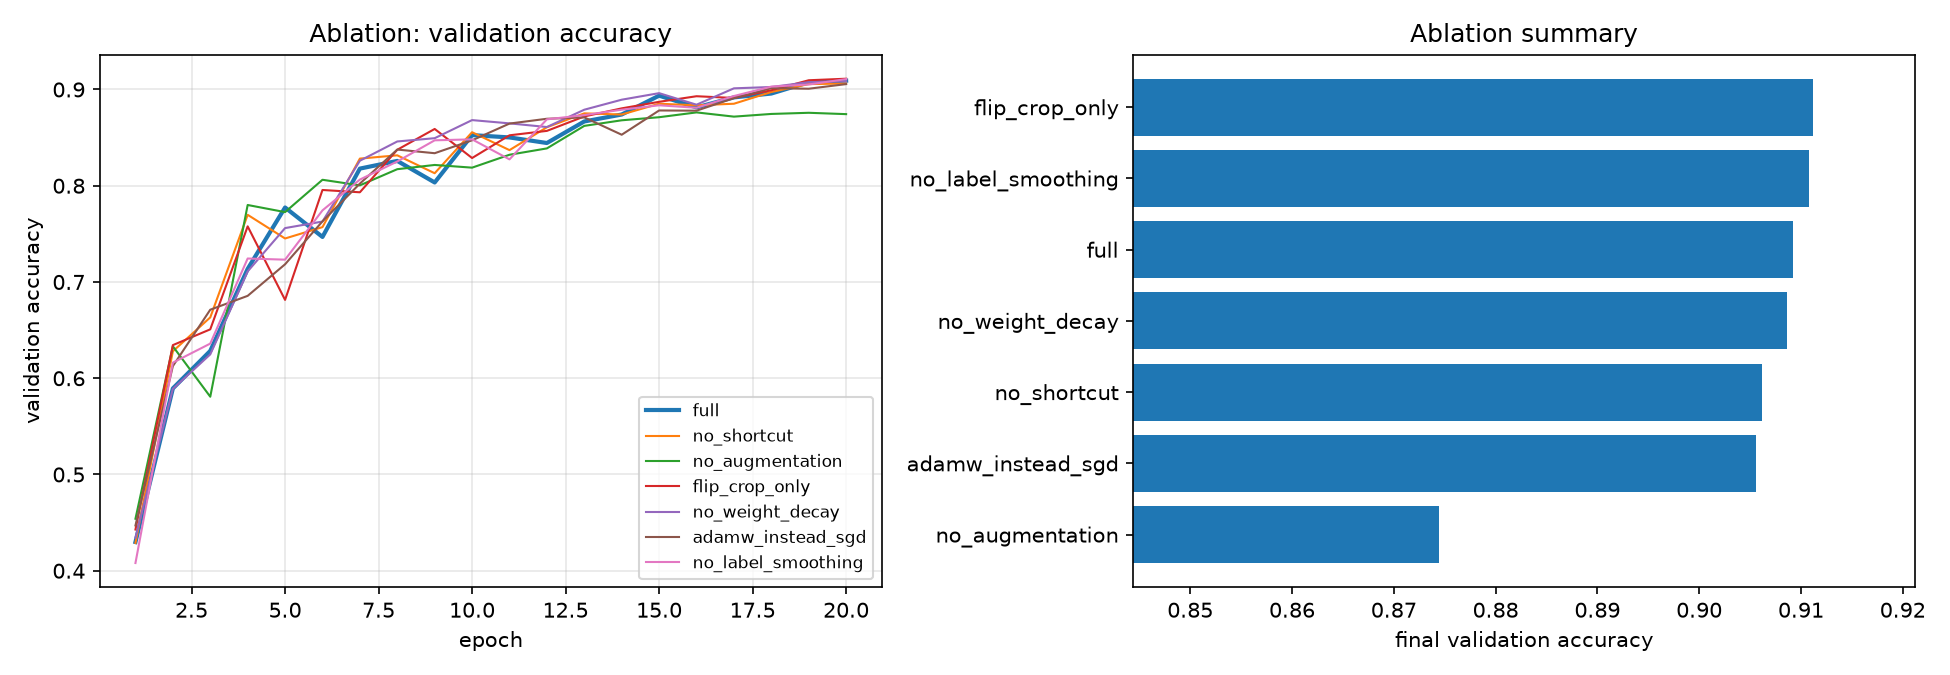

In [31]:
display(Image(filename='results/task4/ablation.png'))

**Discussion**

The final architecture is a scaled-down ResNet-9 (483,424 parameters, under the 500k limit) trained for 20 epochs with SGD + momentum, a one-cycle learning-rate schedule (peak 0.1), weight decay 5e-4, label smoothing 0.1 and flip + crop + cutout augmentation. Each run took about 35 s on the RTX 6000 Ada. Each ablation changes **one** choice relative to `full`:

| Run | Final val acc | Δ vs full |
|---|---|---|
| flip + crop only (no cutout) | **91.12%** | +0.20 |
| no label smoothing | 91.08% | +0.16 |
| full | 90.92% | – |
| no weight decay | 90.86% | −0.06 |
| no shortcut | 90.62% | −0.30 |
| AdamW instead of SGD | 90.56% | −0.36 |
| no augmentation | 87.44% | **−3.48** |

- **Augmentation is the only choice that clearly matters.** Without it the model reaches 100% train accuracy by epoch 16 and validation stops at 87.4%. It memorises, as in Task 3(a).
- **All other differences are within ±0.4 points.** With a single seed and a 5k validation set (1 image = 0.02%), differences of this size are within run-to-run noise, so they should not be over-interpreted:
  - Cutout on top of flip + crop did not help in a 20-epoch budget; the model is not overfitting enough to need it.
  - The shortcut has little effect because this network is shallow; Task 3(b) showed shortcuts matter for deep networks.
  - Label smoothing changes the training loss a lot (0.68 with smoothing vs 0.18 without, since a smoothed target cannot be fitted with zero loss) but barely changes accuracy.
  - Tuned AdamW and tuned SGD perform about the same.
- **Selection:** the configuration with the highest validation accuracy, **flip_crop_only**, was chosen using the validation set only. The test set was then evaluated **once** (the guard file `TEST_EVALUATED.json` prevents re-evaluation).

**Test result: 90.77% test accuracy** (test loss 0.348) with 483,424 parameters.
- This is 0.35 points below its validation accuracy (91.12%). A small drop is expected: choosing the best of 7 runs on validation slightly favours a run that was lucky on that particular split. The gap is small, so the validation set was a reliable stand-in for the test set.

## Use of AI tools

I used Claude (Anthropic's AI assistant) while working on this assignment: to help write and debug the code, set up the Python environment and run the experiments on the GPU server, and to draft parts of the interpretation text. I checked the code and every reported number against the saved results myself, and I understand how each part works.